# Практическая работа №4. Выполнение задач обработки данных в распределённых вычислениях

**Дисциплина:** Технологии и инструментарий анализа больших данных
**Тема:** Физическое выполнение Spark-задач: стадии, партиции, shuffle, стратегии JOIN, кэширование

| | |
|---|---|
| **Выполнил:** | Тагин Никита |
| **Группа:** | ИКБО-61-23 |
| **Дата выполнения:** | 28.10.2026 |
| **Проверил:** | ст. преподаватель Приходько Н.А. |

**Цель работы** — исследовать не только логический результат обработки данных в Apache Spark, но и физический механизм
его получения: связь transformations и actions со стадиями и задачами, влияние числа партиций на параллелизм, shuffle
при широких преобразованиях, выбор стратегии JOIN, повторное вычисление по lineage и эффект `cache()/persist()`.

Работа состоит из двух частей:
1. **Часть I** — учебные эксперименты на таблицах `ecommerce.sqlite` (geolocation, order_items, products, sellers).
2. **Часть II** — самостоятельный эксперимент над связкой **orders ↔ customers** (вариант A, ключ `customer_id`).

Метрики Spark UI (Jobs, Stages, Tasks, Shuffle Read/Write, Storage) снимаются **программно** через REST API Spark UI
(`/api/v1/applications/...`) — это тот же источник данных, который отображают вкладки Jobs/Stages/Storage.
Ключевые представления Spark UI дополнительно приложены скриншотами. В конце — ответы на контрольные вопросы.

# Часть I. Учебные эксперименты

## 3. Экспериментальный стенд и подготовка данных
### Практический блок 3.1. Подготовка окружения

Окружение — Python 3.13 в виртуальном окружении `~/.venvs/tiabd`, JDK 21 (LTS), PySpark 4.2:

```bash
python3.13 -m venv ~/.venvs/tiabd
source ~/.venvs/tiabd/bin/activate
python -m pip install --upgrade pip
python -m pip install pyspark "pandas<3" pyarrow jupyter "nbconvert[webpdf]"
java -version
python -c "import pyspark; print(pyspark.__version__)"
jupyter notebook
```

Окружение намеренно создано в каталоге **без кириллицы** в пути: веб-сервер Spark UI загружает свои статические
ресурсы (CSS/JS) из JAR-файлов PySpark, и при кириллическом пути к JAR (как в практике №3) UI открывается без
оформления и визуализаций DAG. Блокнот выполнен в веб-интерфейсе Jupyter Notebook (Chrome) за один сеанс ядра: *Kernel → Restart Kernel and Run up
to Selected Cell* до предпоследней ячейки, затем, пока SparkSession была жива, сняты скриншоты Spark UI, после чего
выполнена последняя ячейка (`unpersist` + `spark.stop()`). Выводы и скриншоты добавлены в markdown-ячейки по
результатам этого запуска; отчёт выгружен из Jupyter в WebPDF.

В первой ячейке: `JAVA_HOME` указывает на JDK 21; уровень журнала JVM — `error` (файл `spark_conf/log4j2.properties`);
служебный вывод JVM при запуске (`Using incubator modules`, `Setting default log level`) направляется в
`spark_logs/jvm_stderr.log`, чтобы не выглядеть в отчёте как ошибка.

In [1]:
import os, sys, platform, subprocess, contextlib
from pathlib import Path

JDK21 = "/Users/nikita/Library/Java/JavaVirtualMachines/jbr-21.0.6/Contents/Home"
if Path(JDK21).is_dir():
    os.environ["JAVA_HOME"] = JDK21
    os.environ["PATH"] = f"{JDK21}/bin:" + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

SPARK_CONF = Path("spark_conf")
SPARK_CONF.mkdir(exist_ok=True)
(SPARK_CONF / "log4j2.properties").write_text(
    "rootLogger.level = error\n"
    "rootLogger.appenderRef.stdout.ref = console\n"
    "appender.console.type = Console\n"
    "appender.console.name = console\n"
    "appender.console.target = SYSTEM_ERR\n"
    "appender.console.layout.type = PatternLayout\n"
    "appender.console.layout.pattern = %d{yy/MM/dd HH:mm:ss} %p %c{1}: %m%n\n"
)
os.environ["SPARK_CONF_DIR"] = str(SPARK_CONF.resolve())

JVM_LOG = Path("spark_logs/jvm_stderr.log")

@contextlib.contextmanager
def jvm_stderr_to_file(path=JVM_LOG):
    # JVM наследует stderr процесса Python при запуске; на это время stderr
    # направляется в файл. Ошибки Spark всё равно приходят в Python как исключения.
    path.parent.mkdir(exist_ok=True)
    sys.stderr.flush()
    saved = os.dup(2)
    with open(path, "ab") as f:
        os.dup2(f.fileno(), 2)
    try:
        yield
    finally:
        os.dup2(saved, 2)
        os.close(saved)

import pyspark, pandas as pd

def sh(cmd):
    return subprocess.run(cmd, capture_output=True, text=True)

java_ver = sh(["java", "-version"]).stderr.splitlines()[0]
cpu_model = sh(["sysctl", "-n", "machdep.cpu.brand_string"]).stdout.strip() or platform.processor()
mem_gib = int(sh(["sysctl", "-n", "hw.memsize"]).stdout.strip() or 0) / 2**30

print("OS:     ", platform.platform())
print("CPU:    ", cpu_model, "| логических CPU:", os.cpu_count())
print("RAM:    ", f"{mem_gib:.0f} GiB")
print("Python: ", platform.python_version())
print("Java:   ", java_ver)
print("PySpark:", pyspark.__version__)

OS:      macOS-27.0.1-arm64-arm-64bit-Mach-O
CPU:     Apple M1 Pro | логических CPU: 8
RAM:     16 GiB
Python:  3.13.2
Java:    openjdk version "21.0.6" 2025-01-21
PySpark: 4.2.1


### Практический блок 3.2. Staging-каталог из SQLite

Источник — `ecommerce.sqlite` (та же база, что в практике №3). Каталог `spark_input` из прошлой практики не переносился,
поэтому выполняется воспроизводимый экспорт. `read_sql_query(..., chunksize=100_000)` читает крупную `geolocation`
порциями, `mode="a"` дописывает следующие порции в тот же CSV. Кроме таблиц учебной части, экспортируются `orders` и
`customers` для самостоятельного эксперимента. Staging не входит в измеряемые Spark-эксперименты.

In [2]:
import sqlite3

DB_PATH = Path("ecommerce.sqlite")
STAGING = Path("spark_input")
STAGING.mkdir(exist_ok=True)

TABLES = [
    "geolocation", "order_items", "products",
    "sellers", "product_category_name_translation",
    "orders", "customers",          # для самостоятельной части (вариант A)
]

with sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True) as con:
    for table in TABLES:
        out = STAGING / f"{table}.csv"
        first = True
        total = 0
        for chunk in pd.read_sql_query(f"SELECT * FROM {table}", con, chunksize=100_000):
            chunk.to_csv(out, index=False, mode="w" if first else "a",
                         header=first, encoding="utf-8")
            total += len(chunk)
            first = False
        print(f"{table:40s} {total:>9d} rows")

geolocation                                1000163 rows
order_items                                 112650 rows
products                                     32951 rows
sellers                                       3095 rows
product_category_name_translation               71 rows
orders                                       99441 rows
customers                                    99441 rows


### Практический блок 3.3. SparkSession и контролируемая конфигурация

AQE отключён (`spark.sql.adaptive.enabled=false`), чтобы автоматическое объединение shuffle-партиций и смена стратегии
JOIN не мешали причинной интерпретации; `autoBroadcastJoinThreshold=-1` отключает автоматический broadcast;
`shuffle.partitions=8` фиксирует число партиций после shuffle. Spark UI включён; консольный индикатор стадий выключен,
чтобы не засорять вывод ячеек.

In [3]:
from pyspark.sql import SparkSession, functions as F
from pyspark import StorageLevel

with jvm_stderr_to_file():
    spark = (
        SparkSession.builder
        .master("local[*]")
        .appName("Practice4_SparkExecution")
        .config("spark.driver.memory", "4g")
        .config("spark.sql.shuffle.partitions", "8")
        .config("spark.sql.adaptive.enabled", "false")
        .config("spark.sql.autoBroadcastJoinThreshold", "-1")
        .config("spark.ui.showConsoleProgress", "false")
        .getOrCreate()
    )

spark.sparkContext.setLogLevel("WARN")
sc = spark.sparkContext

print("Master:", sc.master)
print("Default parallelism:", sc.defaultParallelism)
print("Shuffle partitions:", spark.conf.get("spark.sql.shuffle.partitions"))
print("AQE:", spark.conf.get("spark.sql.adaptive.enabled"))
print("Spark UI:", sc.uiWebUrl)

Master: local[*]
Default parallelism: 8
Shuffle partitions: 8
AQE: false
Spark UI: http://localhost:4040


**Таблица 2. Паспорт экспериментального стенда**

In [4]:
passport = pd.DataFrame([
    ("ОС", platform.platform()),
    ("CPU", cpu_model),
    ("Python", platform.python_version()),
    ("Java", java_ver),
    ("PySpark / Spark", f"{pyspark.__version__} / {spark.version}"),
    ("Логических CPU", os.cpu_count()),
    ("Оперативная память", f"{mem_gib:.0f} GiB"),
    ("spark.master", sc.master),
    ("spark.default.parallelism", sc.defaultParallelism),
    ("spark.driver.memory", spark.conf.get("spark.driver.memory")),
    ("spark.sql.shuffle.partitions", spark.conf.get("spark.sql.shuffle.partitions")),
    ("spark.sql.adaptive.enabled", spark.conf.get("spark.sql.adaptive.enabled")),
    ("spark.sql.autoBroadcastJoinThreshold", spark.conf.get("spark.sql.autoBroadcastJoinThreshold")),
], columns=["Параметр", "Фактическое значение"])
passport

,Параметр,Фактическое значение
0,ОС,macOS-27.0.1-arm64-arm-64bit-Mach-O
1,CPU,Apple M1 Pro
2,Python,3.13.2
3,Java,"openjdk version ""21.0.6"" 2025-01-21"
4,PySpark / Spark,4.2.1 / 4.2.1
5,Логических CPU,8
6,Оперативная память,16 GiB
7,spark.master,local[*]
8,spark.default.parallelism,8
9,spark.driver.memory,4g


### Инструмент наблюдения: метрики Spark UI через REST API

Spark UI отдаёт свои данные по REST API. Функция `ui_report(group)` берёт все Jobs с заданной job group
(`setJobGroup`), их Stages и для каждой стадии — статус (COMPLETE / SKIPPED), число Tasks, Shuffle Read/Write и Input.
Сводка по эксперименту сохраняется в `UI_LOG` и используется для итоговой таблицы 10. Перед запросом делается пауза
в 1 с: слушатель Spark UI обновляется асинхронно относительно завершения action.

In [5]:
import json, time, urllib.request
from statistics import median
from time import perf_counter

UI_URL, APP_ID = sc.uiWebUrl, sc.applicationId
UI_LOG = {}

def ui_get(path):
    with urllib.request.urlopen(f"{UI_URL}/api/v1/applications/{APP_ID}/{path}") as r:
        return json.load(r)

def kib(b):
    return round(b / 1024, 1)

def ui_report(group, label=None, show=True):
    time.sleep(1.0)
    jobs = sorted((j for j in ui_get("jobs") if j.get("jobGroup") == group), key=lambda j: j["jobId"])
    rows = []
    for j in jobs:
        for sid in sorted(j["stageIds"]):
            st = ui_get(f"stages/{sid}")[0]
            rows.append({
                "job": j["jobId"], "stage": sid, "status": st["status"], "tasks": st["numTasks"],
                "input_KiB": kib(st["inputBytes"]),
                "shuffle_read_KiB": kib(st["shuffleReadBytes"]),
                "shuffle_write_KiB": kib(st["shuffleWriteBytes"]),
                "name": st["name"][:45],
            })
    df = pd.DataFrame(rows)
    if df.empty:
        print(f"[{group}] Jobs не найдено")
        return df
    done = df[df.status == "COMPLETE"]
    summary = {
        "Jobs": len(jobs),
        "Stages (complete / skipped)": f"{len(done)} / {int((df.status == 'SKIPPED').sum())}",
        "Tasks по стадиям": " → ".join(str(t) for t in done.tasks),
        "Shuffle Write, KiB": float(round(done.shuffle_write_KiB.sum(), 1)),
        "Shuffle Read, KiB": float(round(done.shuffle_read_KiB.sum(), 1)),
    }
    if label:
        UI_LOG[label] = summary
    if show:
        print(f"[{group}]", summary)
        display(df)
    return df

def jobs_in_group(group):
    return list(sc.statusTracker().getJobIdsForGroup(group))

### Практический блок 3.4. Чтение исходных таблиц и перевод в Parquet

`inferSchema` используется только на подготовительном чтении CSV; эксперименты выполняются над Parquet.

In [6]:
PARQUET = Path("spark_input_parquet")
PARQUET.mkdir(exist_ok=True)

sc.setJobGroup("P4_PREP", "Подготовка: CSV -> Parquet")
for name in TABLES:
    df = spark.read.option("header", True).option("inferSchema", True).csv(str(STAGING / f"{name}.csv"))
    df.write.mode("overwrite").parquet(str(PARQUET / name))

geo = spark.read.parquet(str(PARQUET / "geolocation"))
items = spark.read.parquet(str(PARQUET / "order_items"))
products = spark.read.parquet(str(PARQUET / "products"))
sellers = spark.read.parquet(str(PARQUET / "sellers"))
translations = spark.read.parquet(str(PARQUET / "product_category_name_translation"))

print(geo.count(), items.count(), products.count(), sellers.count(), translations.count())
for name in TABLES:
    files = list((PARQUET / name).glob("part-*.parquet"))
    print(f"{name:36s} parquet-файлов: {len(files)}")

1000163 112650 32951 3095 71
geolocation                          parquet-файлов: 8
order_items                          parquet-файлов: 4
products                             parquet-файлов: 1
sellers                              parquet-файлов: 1
product_category_name_translation    parquet-файлов: 1
orders                               parquet-файлов: 5
customers                            parquet-файлов: 3


## 4. Spark UI как измерительный инструмент
### Практический блок 4.1. Маркировка экспериментов

`setJobGroup(groupId, description)` подписывает последующие Jobs; план от этого не меняется.

In [7]:
sc.setJobGroup("P4_BASELINE", "Практика 4: базовая проверка Spark UI", interruptOnCancel=True)
_ = items.count()
_ = ui_report("P4_BASELINE")

[P4_BASELINE] {'Jobs': 1, 'Stages (complete / skipped)': '2 / 0', 'Tasks по стадиям': '4 → 1', 'Shuffle Write, KiB': 0.2, 'Shuffle Read, KiB': 0.2}


,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,31,36,COMPLETE,4,24.9,0.0,0.2,count at DirectMethodHandleAccessor.java:103
1,31,37,COMPLETE,1,0.0,0.2,0.0,count at DirectMethodHandleAccessor.java:103


**Наблюдение.** `items.count()` с подписью P4_BASELINE дал 1 Job из 2 стадий: 4 задачи чтения (по одной на каждый из 4 Parquet-файлов `order_items`) и 1 задача, которая собирает частичные счётчики (Shuffle 0,2 KiB). Даже простой `count()` устроен как частичная агрегация и маленький обмен данными.

## 5. Исследование ленивых вычислений
### Практический блок 5.1. Цепочка transformations без Action

In [8]:
sc.setJobGroup("P4_LAZY", "Lazy evaluation")

t0 = perf_counter()
geo_prepared = (
    geo
    .select("geolocation_zip_code_prefix", "geolocation_state",
            "geolocation_lat", "geolocation_lng")
    .filter(F.col("geolocation_state").isNotNull())
    .withColumn("abs_lat", F.abs(F.col("geolocation_lat")))
)
t_plan = perf_counter() - t0

print(type(geo_prepared).__name__)
print(f"Построение DataFrame: {t_plan * 1000:.1f} мс")
time.sleep(1.0)
print("Jobs в группе P4_LAZY до Action:", jobs_in_group("P4_LAZY"))

DataFrame
Построение DataFrame: 58.4 мс
Jobs в группе P4_LAZY до Action: []


### Практический блок 5.2. Action как момент запуска вычисления

In [9]:
t0 = perf_counter()
n = geo_prepared.count()
elapsed = perf_counter() - t0

print("Rows:", n)
print(f"Elapsed: {elapsed:.3f} s")
print("Jobs в группе P4_LAZY после Action:", jobs_in_group("P4_LAZY"))
_ = ui_report("P4_LAZY")

Rows: 1000163
Elapsed: 0.214 s
Jobs в группе P4_LAZY после Action: [32]
[P4_LAZY] {'Jobs': 1, 'Stages (complete / skipped)': '2 / 0', 'Tasks по стадиям': '8 → 1', 'Shuffle Write, KiB': 0.5, 'Shuffle Read, KiB': 0.5}


,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,32,38,COMPLETE,8,84.1,0.0,0.5,count at DirectMethodHandleAccessor.java:103
1,32,39,COMPLETE,1,0.0,0.5,0.0,count at DirectMethodHandleAccessor.java:103


**Наблюдение.** Объект `geo_prepared` был построен за 58 мс, и в группе P4_LAZY не появилось ни одного Job (`[]`): `select`, `filter` и `withColumn` только описали план. Job 32 возник только после `count()`: 0,214 с, стадии 8 → 1 задач, Input 84 KiB (Spark прочитал из Parquet только нужные столбцы). Число строк осталось 1 000 163: пустых значений `geolocation_state` в таблице нет.

## 6. Исследование партиций и параллелизма
### Практический блок 6.1. Число партиций и распределение строк

In [10]:
print("Input partitions:", geo.rdd.getNumPartitions())
print("Default parallelism:", sc.defaultParallelism)

sc.setJobGroup("P4_PARTITIONS", "Распределение строк geolocation по входным партициям")
partition_sizes = (
    geo
    .select(F.spark_partition_id().alias("pid"))
    .groupBy("pid")
    .count()
    .orderBy("pid")
)
partition_sizes.show(100, truncate=False)
_ = ui_report("P4_PARTITIONS")

Input partitions: 8
Default parallelism: 8
+---+------+
|pid|count |
+---+------+
|0  |134518|
|1  |132908|
|2  |130331|
|3  |132762|
|4  |133452|
|5  |138921|
|6  |128830|
|7  |68441 |
+---+------+

[P4_PARTITIONS] {'Jobs': 1, 'Stages (complete / skipped)': '2 / 0', 'Tasks по стадиям': '8 → 8', 'Shuffle Write, KiB': 0.5, 'Shuffle Read, KiB': 0.5}


,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,33,40,COMPLETE,8,48.8,0.0,0.5,showString at DirectMethodHandleAccessor.java
1,33,41,COMPLETE,8,0.0,0.5,0.0,showString at DirectMethodHandleAccessor.java


**Наблюдение.** `geolocation` записан в 8 Parquet-файлов, и после чтения у DataFrame 8 входных партиций. Это совпадает с 8 задачами первой стадии и с `defaultParallelism = 8`: все 8 логических ядер загружены. Партиции 0–6 содержат 129–139 тыс. строк, партиция 7 — 68 тыс. (в последний файл попал остаток), поэтому её задача короче остальных.

### Практический блок 6.2. Реальный перекос по geolocation_state

In [11]:
total_geo = geo.count()
state_counts = (
    geo
    .groupBy("geolocation_state")
    .count()
    .withColumn("share_pct", F.round(F.col("count") / total_geo * 100, 2))
    .orderBy(F.desc("count"))
)
print("Штатов:", state_counts.count())
state_counts.show(5, truncate=False)

Штатов: 27
+-----------------+------+---------+
|geolocation_state|count |share_pct|
+-----------------+------+---------+
|SP               |404268|40.42    |
|MG               |126336|12.63    |
|RJ               |121169|12.11    |
|RS               |61851 |6.18     |
|PR               |57859 |5.78     |
+-----------------+------+---------+
only showing top 5 rows


**Наблюдение.** В таблице 27 штатов, и они распределены очень неравномерно: на SP приходится 404 268 строк (40,42 %), на MG и RJ — около 12 % каждый, на остальные 24 штата вместе — около 35 %. Это свойство самих данных: при разбиении по штату партиция с SP неизбежно окажется самой крупной.

## 7. Сравнение repartition() и coalesce()
### Практический блок 7.1. Контролируемое уменьшение партиций

In [12]:
skewed16 = geo.repartition(16, "geolocation_state")
repart4 = skewed16.repartition(4)
coal4 = skewed16.coalesce(4)

print("skewed16:", skewed16.rdd.getNumPartitions())
print("repart4:", repart4.rdd.getNumPartitions())
print("coal4:", coal4.rdd.getNumPartitions())

skewed16: 16
repart4: 4
coal4: 4


### Практический блок 7.2. Физические планы

In [13]:
print("=== repartition(4) ===")
repart4.explain("formatted")

print("=== coalesce(4) ===")
coal4.explain("formatted")

=== repartition(4) ===
== Physical Plan ==
Exchange (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [6]: [geolocation_id#201, geolocation_zip_code_prefix#202, geolocation_lat#203, geolocation_lng#204, geolocation_city#205, geolocation_state#206]
Batched: true
Location: InMemoryFileIndex [file:/Users/nikita/Desktop/Большие данные/4 практика/spark_input_parquet/geolocation]
ReadSchema: struct<geolocation_id:int,geolocation_zip_code_prefix:int,geolocation_lat:double,geolocation_lng:double,geolocation_city:string,geolocation_state:string>

(2) ColumnarToRow [codegen id : 1]
Input [6]: [geolocation_id#201, geolocation_zip_code_prefix#202, geolocation_lat#203, geolocation_lng#204, geolocation_city#205, geolocation_state#206]

(3) Exchange
Input [6]: [geolocation_id#201, geolocation_zip_code_prefix#202, geolocation_lat#203, geolocation_lng#204, geolocation_city#205, geolocation_state#206]
Arguments: RoundRobinPartitioning(4), REPARTITION_BY_NUM, [plan_id=653]


=

### Практический блок 7.3. Размеры выходных партиций и стоимость

Профиль партиций строится одной и той же функцией для обоих вариантов. Дополнительно каждый вариант
материализуется `count()` в своей job group, чтобы сравнить Stages и объём shuffle в Spark UI.

In [14]:
def partition_profile(df):
    return (
        df
        .select(F.spark_partition_id().alias("pid"))
        .groupBy("pid")
        .count()
        .orderBy("pid")
    )

prof_rows = []
for label, df in [("repartition(4)", repart4), ("coalesce(4)", coal4)]:
    prof = partition_profile(df).toPandas()
    print(label)
    print(prof.to_string(index=False))
    c = prof["count"]
    prof_rows.append({"Вариант": label, "min rows": int(c.min()), "max rows": int(c.max()),
                      "mean rows": round(c.mean(), 1), "max/mean": round(c.max() / c.mean(), 2)})

sc.setJobGroup("P4_REPART4", "repartition(4) после repartition(16, state)")
t0 = perf_counter(); repart4.count(); t_rep = perf_counter() - t0
sc.setJobGroup("P4_COAL4", "coalesce(4) после repartition(16, state)")
t0 = perf_counter(); coal4.count(); t_coal = perf_counter() - t0
prof_rows[0]["count(), с"] = round(t_rep, 3)
prof_rows[1]["count(), с"] = round(t_coal, 3)

repartition(4)
 pid  count
   0 250040
   1 250041
   2 250041
   3 250041
coalesce(4)
 pid  count
   0 195064
   1 626485
   2  90152
   3  88462


**Таблица 4. Распределение строк по партициям**

In [15]:
table4 = pd.DataFrame(prof_rows)
table4

,Вариант,min rows,max rows,mean rows,max/mean,"count(), с"
0,repartition(4),250040,250041,250040.8,1.00,0.331
1,coalesce(4),88462,626485,250040.8,2.51,0.161


In [16]:
_ = ui_report("P4_REPART4", "repartition(4)")
_ = ui_report("P4_COAL4", "coalesce(4)")

[P4_REPART4] {'Jobs': 1, 'Stages (complete / skipped)': '4 / 0', 'Tasks по стадиям': '8 → 16 → 4 → 1', 'Shuffle Write, KiB': 173.1, 'Shuffle Read, KiB': 173.1}


,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,41,65,COMPLETE,8,48.8,0.0,152.2,count at DirectMethodHandleAccessor.java:103
1,41,66,COMPLETE,16,0.0,152.2,20.7,count at DirectMethodHandleAccessor.java:103
2,41,67,COMPLETE,4,0.0,20.7,0.2,count at DirectMethodHandleAccessor.java:103
3,41,68,COMPLETE,1,0.0,0.2,0.0,count at DirectMethodHandleAccessor.java:103


[P4_COAL4] {'Jobs': 1, 'Stages (complete / skipped)': '3 / 0', 'Tasks по стадиям': '8 → 4 → 1', 'Shuffle Write, KiB': 152.4, 'Shuffle Read, KiB': 152.4}


,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,42,69,COMPLETE,8,48.8,0.0,152.2,count at DirectMethodHandleAccessor.java:103
1,42,70,COMPLETE,4,0.0,152.2,0.2,count at DirectMethodHandleAccessor.java:103
2,42,71,COMPLETE,1,0.0,0.2,0.0,count at DirectMethodHandleAccessor.java:103


**Вывод.** Обе ветки начинаются с одного и того же `Exchange hashpartitioning(geolocation_state, 16)`. Дальше `repartition(4)` добавил второй `Exchange RoundRobinPartitioning(4)`, а `coalesce(4)` — оператор `Coalesce 4` без нового обмена. Spark UI это подтверждает: у repartition 4 стадии (8 → 16 → 4 → 1) и Shuffle Write 173,1 KiB, у coalesce 3 стадии (8 → 4 → 1) и 152,4 KiB. На моём стенде coalesce оказался быстрее (0,161 с против 0,331 с), но сохранил перекос: размеры партиций от 88 тыс. до 626 тыс. строк (max/mean = 2,51), потому что он склеил целые hash-партиции, и одна из них содержала SP. repartition разложил строки почти поровну, по 250 040–250 041 (max/mean = 1,00).

## 8. Shuffle на примере groupBy()
### Практический блок 8.1. Агрегация order_items по продавцам

In [17]:
sc.setJobGroup("P4_GROUPBY", "Shuffle: groupBy seller_id")

seller_stats = (
    items
    .groupBy("seller_id")
    .agg(
        F.count("*").alias("items"),
        F.round(F.sum("price"), 2).alias("revenue"),
        F.round(F.avg("price"), 2).alias("avg_price")
    )
    .orderBy(F.desc("revenue"))
)

seller_stats.show(5, truncate=False)
_ = ui_report("P4_GROUPBY", "groupBy seller_id")

+--------------------------------+-----+---------+---------+
|seller_id                       |items|revenue  |avg_price|
+--------------------------------+-----+---------+---------+
|4869f7a5dfa277a7dca6462dcf3b52b2|1156 |229472.63|198.51   |
|53243585a1d6dc2643021fd1853d8905|410  |222776.05|543.36   |
|4a3ca9315b744ce9f8e9374361493884|1987 |200472.92|100.89   |
|fa1c13f2614d7b5c4749cbc52fecda94|586  |194042.03|331.13   |
|7c67e1448b00f6e969d365cea6b010ab|1364 |187923.89|137.77   |
+--------------------------------+-----+---------+---------+
only showing top 5 rows
[P4_GROUPBY] {'Jobs': 1, 'Stages (complete / skipped)': '2 / 0', 'Tasks по стадиям': '4 → 8', 'Shuffle Write, KiB': 437.8, 'Shuffle Read, KiB': 437.8}


,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,43,72,COMPLETE,4,24.9,0.0,437.8,showString at DirectMethodHandleAccessor.java
1,43,73,COMPLETE,8,0.0,437.8,0.0,showString at DirectMethodHandleAccessor.java


**Рисунок.** Spark UI → Jobs → детали Job группы P4_GROUPBY: стадии, Tasks, Shuffle Read/Write

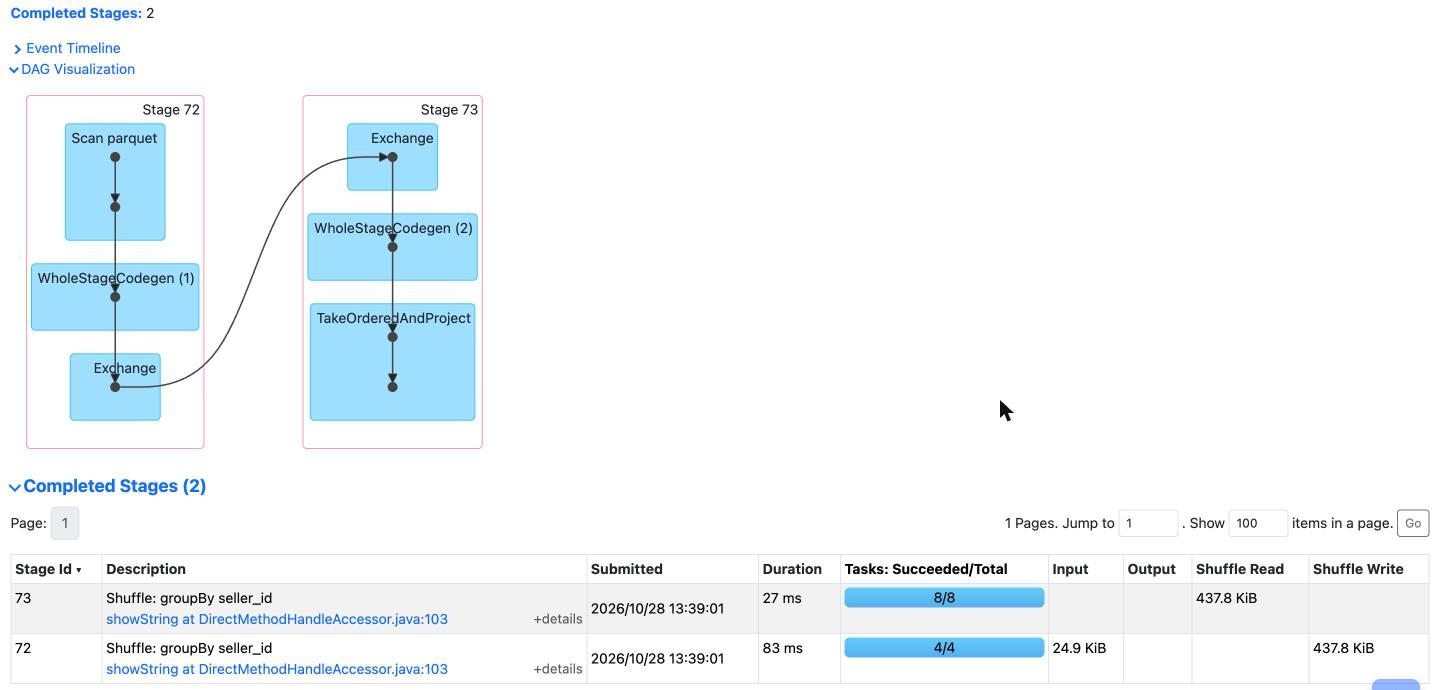

### Практический блок 8.2. Физический план groupBy()

In [18]:
seller_stats.explain("formatted")

== Physical Plan ==
* Sort (7)
+- Exchange (6)
   +- * HashAggregate (5)
      +- Exchange (4)
         +- * HashAggregate (3)
            +- * ColumnarToRow (2)
               +- Scan parquet  (1)


(1) Scan parquet 
Output [2]: [seller_id#210, price#212]
Batched: true
Location: InMemoryFileIndex [file:/Users/nikita/Desktop/Большие данные/4 практика/spark_input_parquet/order_items]
ReadSchema: struct<seller_id:string,price:double>

(2) ColumnarToRow [codegen id : 1]
Input [2]: [seller_id#210, price#212]

(3) HashAggregate [codegen id : 1]
Input [2]: [seller_id#210, price#212]
Keys [1]: [seller_id#210]
Functions [3]: [partial_count(1), partial_sum(price#212), partial_avg(price#212)]
Aggregate Attributes [4]: [count#400L, sum#401, sum#402, count#403L]
Results [5]: [seller_id#210, count#404L, sum#405, sum#406, count#407L]

(4) Exchange
Input [5]: [seller_id#210, count#404L, sum#405, sum#406, count#407L]
Arguments: hashpartitioning(seller_id#210, 8), ENSURE_REQUIREMENTS, [plan_id=1051]

(

**Вывод.** `groupBy(seller_id)` выполнен как частичная агрегация (`partial_count/sum/avg`), затем `Exchange hashpartitioning(seller_id, 8)` и финальная агрегация. В Spark UI это 2 стадии: 4 задачи (по Parquet-файлам) записали 437,8 KiB shuffle, 8 задач (по `shuffle.partitions`) прочитали те же 437,8 KiB. В `explain()` есть и второй Exchange — `rangepartitioning(revenue DESC)` для `orderBy`. При `show(5)` Spark заменил полную сортировку на `TakeOrderedAndProject` (виден на DAG), поэтому третьей стадии нет. Это пример того, что план DataFrame и фактическое выполнение конкретного action могут отличаться.

## 9. Анализ плана через explain("formatted")
### Практический блок 9.1. Чтение плана снизу вверх

In [19]:
plan_demo = (
    items
    .filter(F.col("price") >= 100)
    .select("seller_id", "price", "freight_value")
    .withColumn("gross", F.col("price") + F.col("freight_value"))
    .groupBy("seller_id")
    .agg(F.round(F.sum("gross"), 2).alias("gross_sum"))
)

plan_demo.explain("formatted")

== Physical Plan ==
* HashAggregate (7)
+- Exchange (6)
   +- * HashAggregate (5)
      +- * Project (4)
         +- * Filter (3)
            +- * ColumnarToRow (2)
               +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [seller_id#210, price#212, freight_value#213]
Batched: true
Location: InMemoryFileIndex [file:/Users/nikita/Desktop/Большие данные/4 практика/spark_input_parquet/order_items]
PushedFilters: [IsNotNull(price), GreaterThanOrEqual(price,100.0)]
ReadSchema: struct<seller_id:string,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 1]
Input [3]: [seller_id#210, price#212, freight_value#213]

(3) Filter [codegen id : 1]
Input [3]: [seller_id#210, price#212, freight_value#213]
Condition : (isnotnull(price#212) AND (price#212 >= 100.0))

(4) Project [codegen id : 1]
Output [2]: [seller_id#210, (price#212 + freight_value#213) AS gross#429]
Input [3]: [seller_id#210, price#212, freight_value#213]

(5) HashAggregate [codegen id : 1]
Input [2]: [seller

**Разбор плана (снизу вверх).** `Scan parquet` читает `order_items`, причём фильтр передан в источник: `PushedFilters: [IsNotNull(price), GreaterThanOrEqual(price,100.0)]`. `Filter` отбрасывает строки до любого обмена. `Project` оставляет 3 столбца и вычисляет `gross`. `HashAggregate (partial_sum)` суммирует внутри каждой партиции, `Exchange hashpartitioning(seller_id, 8)` — единственная граница shuffle, финальный `HashAggregate (sum)` завершает стадию. По сети передаются уже частичные суммы по продавцам, а не отфильтрованные строки.

## 10. Sort Merge Join и Broadcast Hash Join
### Практический блок 10.1. Sort Merge Join при отключённом broadcast

In [20]:
sc.setJobGroup("P4_SMJ", "Sort Merge Join: items x products")

smj = items.hint("merge").join(products.hint("merge"), on="product_id", how="inner")

smj.explain("formatted")
print("Rows:", smj.count())
_ = ui_report("P4_SMJ", "Sort Merge Join")

== Physical Plan ==
* Project (12)
+- * SortMergeJoin Inner (11)
   :- * Sort (5)
   :  +- Exchange (4)
   :     +- * Filter (3)
   :        +- * ColumnarToRow (2)
   :           +- Scan parquet  (1)
   +- * Sort (10)
      +- Exchange (9)
         +- * Filter (8)
            +- * ColumnarToRow (7)
               +- Scan parquet  (6)


(1) Scan parquet 
Output [7]: [order_id#207, order_item_id#208, product_id#209, seller_id#210, shipping_limit_date#211, price#212, freight_value#213]
Batched: true
Location: InMemoryFileIndex [file:/Users/nikita/Desktop/Большие данные/4 практика/spark_input_parquet/order_items]
PushedFilters: [IsNotNull(product_id)]
ReadSchema: struct<order_id:string,order_item_id:int,product_id:string,seller_id:string,shipping_limit_date:timestamp,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 1]
Input [7]: [order_id#207, order_item_id#208, product_id#209, seller_id#210, shipping_limit_date#211, price#212, freight_value#213]

(3) Filter [codegen id 

,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,44,74,COMPLETE,4,44.4,0.0,2743.3,count at DirectMethodHandleAccessor.java:103
1,44,75,COMPLETE,1,13.3,0.0,1088.3,count at DirectMethodHandleAccessor.java:103
2,44,76,COMPLETE,8,0.0,3831.6,0.5,count at DirectMethodHandleAccessor.java:103
3,44,77,COMPLETE,1,0.0,0.5,0.0,count at DirectMethodHandleAccessor.java:103


**Рисунок.** Spark UI → SQL / DataFrame → план запроса Sort Merge Join (Exchange + Sort с обеих сторон)

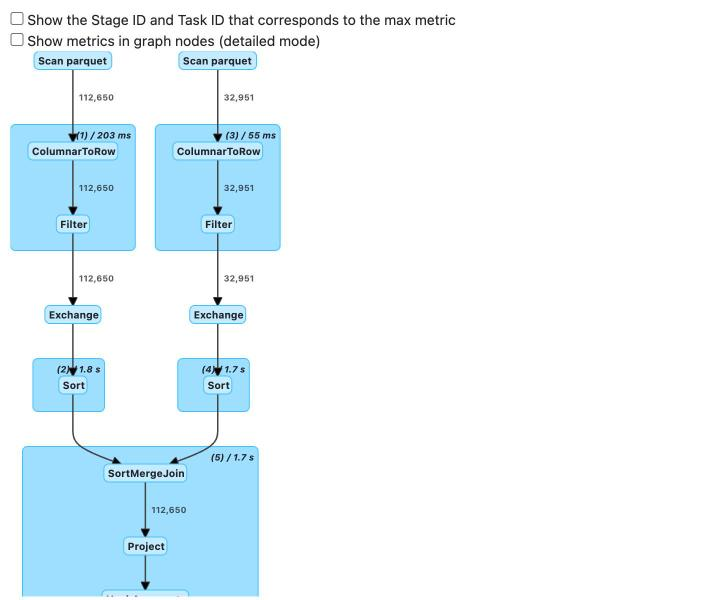

### Практический блок 10.2. Broadcast Hash Join

In [21]:
sc.setJobGroup("P4_BHJ", "Broadcast Hash Join: items x products")

bhj = items.join(F.broadcast(products), on="product_id", how="inner")

bhj.explain("formatted")
print("Rows:", bhj.count())
_ = ui_report("P4_BHJ", "Broadcast Hash Join")

== Physical Plan ==
* Project (9)
+- * BroadcastHashJoin Inner BuildRight (8)
   :- * Filter (3)
   :  +- * ColumnarToRow (2)
   :     +- Scan parquet  (1)
   +- BroadcastExchange (7)
      +- * Filter (6)
         +- * ColumnarToRow (5)
            +- Scan parquet  (4)


(1) Scan parquet 
Output [7]: [order_id#207, order_item_id#208, product_id#209, seller_id#210, shipping_limit_date#211, price#212, freight_value#213]
Batched: true
Location: InMemoryFileIndex [file:/Users/nikita/Desktop/Большие данные/4 практика/spark_input_parquet/order_items]
PushedFilters: [IsNotNull(product_id)]
ReadSchema: struct<order_id:string,order_item_id:int,product_id:string,seller_id:string,shipping_limit_date:timestamp,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 2]
Input [7]: [order_id#207, order_item_id#208, product_id#209, seller_id#210, shipping_limit_date#211, price#212, freight_value#213]

(3) Filter [codegen id : 2]
Input [7]: [order_id#207, order_item_id#208, product_id#209,

,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,45,78,COMPLETE,1,13.3,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Complet
1,46,79,COMPLETE,4,44.4,0.0,0.2,count at DirectMethodHandleAccessor.java:103
2,46,80,COMPLETE,1,0.0,0.2,0.0,count at DirectMethodHandleAccessor.java:103


**Рисунок.** Spark UI → SQL / DataFrame → план запроса Broadcast Hash Join (BroadcastExchange, без Exchange большой стороны)

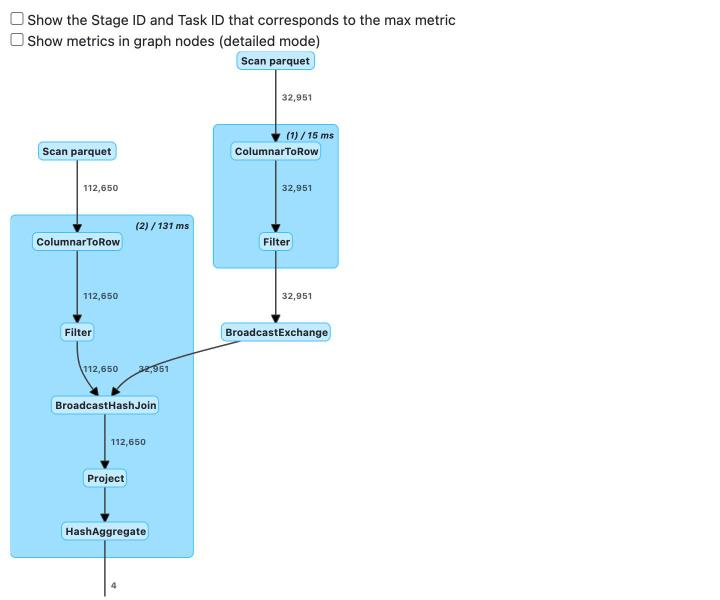

### Практический блок 10.3. Сравнительная таблица JOIN-стратегий

Время измеряется отдельно от первого запуска: 3 повтора `count()` для каждой стратегии, итог — медиана.

In [22]:
def timed(fn, repeats=3):
    times = []
    for _ in range(repeats):
        t0 = perf_counter()
        fn()
        times.append(perf_counter() - t0)
    return [round(t, 3) for t in times], round(median(times), 3)

sc.setJobGroup("P4_JOIN_TIMING", "Повторные замеры JOIN")
smj_times, smj_med = timed(smj.count)
bhj_times, bhj_med = timed(bhj.count)
print("SMJ:", smj_times, "median", smj_med)
print("BHJ:", bhj_times, "median", bhj_med)

def exchange_big_side(df):
    plan = df._jdf.queryExecution().executedPlan().toString()
    return "да (hashpartitioning product_id)" if "Exchange hashpartitioning(product_id" in plan else "нет"

table6 = pd.DataFrame({
    "Показатель": ["Строк результата", "Exchange большой стороны", "Shuffle Write / Read, KiB",
                   "Jobs / Stages (complete/skipped)", "Tasks по стадиям", "Время (медиана 3 запусков), с"],
    "Sort Merge Join": [smj.count(), exchange_big_side(smj),
                        f'{UI_LOG["Sort Merge Join"]["Shuffle Write, KiB"]} / {UI_LOG["Sort Merge Join"]["Shuffle Read, KiB"]}',
                        f'{UI_LOG["Sort Merge Join"]["Jobs"]} / {UI_LOG["Sort Merge Join"]["Stages (complete / skipped)"]}',
                        UI_LOG["Sort Merge Join"]["Tasks по стадиям"], smj_med],
    "Broadcast Hash Join": [bhj.count(), exchange_big_side(bhj),
                            f'{UI_LOG["Broadcast Hash Join"]["Shuffle Write, KiB"]} / {UI_LOG["Broadcast Hash Join"]["Shuffle Read, KiB"]}',
                            f'{UI_LOG["Broadcast Hash Join"]["Jobs"]} / {UI_LOG["Broadcast Hash Join"]["Stages (complete / skipped)"]}',
                            UI_LOG["Broadcast Hash Join"]["Tasks по стадиям"], bhj_med],
})
table6

SMJ: [0.216, 0.124, 0.104] median 0.124
BHJ: [0.123, 0.101, 0.129] median 0.123


,Показатель,Sort Merge Join,Broadcast Hash Join
0,Строк результата,112650,112650
1,Exchange большой стороны,да (hashpartitioning product_id),нет
2,"Shuffle Write / Read, KiB",3832.1 / 3832.1,0.2 / 0.2
3,Jobs / Stages (complete/skipped),1 / 4 / 0,2 / 3 / 0
4,Tasks по стадиям,4 → 1 → 8 → 1,1 → 4 → 1
5,"Время (медиана 3 запусков), с",0.124,0.123


**Вывод.** Оба запроса вернули 112 650 строк, то есть логически они эквивалентны. Sort Merge Join перемешивает обе стороны по `product_id` (`Exchange hashpartitioning(product_id, 8)` + `Sort` слева и справа): 4 стадии, Shuffle Write/Read 3 832 KiB, из них 2 743 KiB даёт `order_items`. Broadcast Hash Join собирает `products` отдельным Job (1 задача) и рассылает его через `BroadcastExchange`. `order_items` при этом не перемешивается: остаётся только служебный shuffle 0,2 KiB для итогового `count`. Медианное время на моём стенде почти одинаковое (0,124 с против 0,123 с): при 112 тыс. строк и локальном диске обмен в 3,7 MiB стоит мало. Выигрыш BHJ здесь виден в объёме shuffle, а не во времени.

## 11. Исследование cache() / persist()
### Практический блок 11.1. Повторно используемый промежуточный DataFrame

In [23]:
spark.catalog.clearCache()

products_small = products.select("product_id", "product_category_name")
sellers_small = sellers.select("seller_id", "seller_state")

joined = (
    items
    .join(F.broadcast(products_small), "product_id", "left")
    .join(F.broadcast(sellers_small), "seller_id", "left")
    .withColumn("gross_value", F.col("price") + F.col("freight_value"))
)

def action_category(df):
    return (
        df.groupBy("product_category_name")
        .agg(F.sum("gross_value").alias("gross"))
        .agg(F.sum("gross").alias("checksum"))
        .first()[0]
    )

def action_state(df):
    return (
        df.groupBy("seller_state")
        .agg(F.sum("gross_value").alias("gross"))
        .agg(F.sum("gross").alias("checksum"))
        .first()[0]
    )

### Практический блок 11.2. Измерение без persist()

In [24]:
sc.setJobGroup("P4_NOCACHE", "Два действия без сохранения")

t0 = perf_counter()
chk1 = action_category(joined)
t1 = perf_counter()
chk2 = action_state(joined)
t2 = perf_counter()

nocache = (round(t1 - t0, 3), round(t2 - t1, 3))
print(f"Action 1: {nocache[0]:.3f} s, checksum = {chk1:.2f}")
print(f"Action 2: {nocache[1]:.3f} s, checksum = {chk2:.2f}")
print("is_cached:", joined.is_cached)
_ = ui_report("P4_NOCACHE", "без persist")

Action 1: 0.264 s, checksum = 15843553.24
Action 2: 0.222 s, checksum = 15843553.24
is_cached: False
[P4_NOCACHE] {'Jobs': 6, 'Stages (complete / skipped)': '10 / 0', 'Tasks по стадиям': '1 → 1 → 4 → 8 → 1 → 1 → 1 → 4 → 8 → 1', 'Shuffle Write, KiB': 15.6, 'Shuffle Read, KiB': 15.6}


,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,59,109,COMPLETE,1,4.2,0.0,0.0,first at /var/folders/qy/jz75c5852d327vzwrtbp
1,60,110,COMPLETE,1,13.3,0.0,0.0,first at /var/folders/qy/jz75c5852d327vzwrtbp
2,61,111,COMPLETE,4,24.9,0.0,11.5,first at /var/folders/qy/jz75c5852d327vzwrtbp
3,61,112,COMPLETE,8,0.0,11.5,0.5,first at /var/folders/qy/jz75c5852d327vzwrtbp
4,61,113,COMPLETE,1,0.0,0.5,0.0,first at /var/folders/qy/jz75c5852d327vzwrtbp
5,62,114,COMPLETE,1,13.3,0.0,0.0,first at /var/folders/qy/jz75c5852d327vzwrtbp
6,63,115,COMPLETE,1,4.2,0.0,0.0,first at /var/folders/qy/jz75c5852d327vzwrtbp
7,64,116,COMPLETE,4,24.9,0.0,3.1,first at /var/folders/qy/jz75c5852d327vzwrtbp
8,64,117,COMPLETE,8,0.0,3.1,0.5,first at /var/folders/qy/jz75c5852d327vzwrtbp
9,64,118,COMPLETE,1,0.0,0.5,0.0,first at /var/folders/qy/jz75c5852d327vzwrtbp


### Практический блок 11.3. persist(MEMORY_AND_DISK) и материализация

In [25]:
sc.setJobGroup("P4_CACHE", "persist + повторные Actions")

cached = joined.persist(StorageLevel.MEMORY_AND_DISK)
print("После persist:", cached.is_cached)

t0 = perf_counter()
materialized_rows = cached.count()          # первый Action заполняет кэш
t1 = perf_counter()
chk1c = action_category(cached)
t2 = perf_counter()
chk2c = action_state(cached)
t3 = perf_counter()

withcache = (round(t1 - t0, 3), round(t2 - t1, 3), round(t3 - t2, 3))
print("Rows:", materialized_rows)
print(f"Materialization: {withcache[0]:.3f} s")
print(f"Cached action 1: {withcache[1]:.3f} s, checksum = {chk1c:.2f}")
print(f"Cached action 2: {withcache[2]:.3f} s, checksum = {chk2c:.2f}")
print("Контрольные суммы совпадают:", round(chk1, 2) == round(chk1c, 2) and round(chk2, 2) == round(chk2c, 2))

time.sleep(1.0)
for r in ui_get("storage/rdd"):
    print(f"Storage: {r['name'][:60]} | {r['storageLevel']} | партиций в кэше {r['numCachedPartitions']} "
          f"| память {kib(r['memoryUsed'])} KiB | диск {kib(r['diskUsed'])} KiB")
_ = ui_report("P4_CACHE", "persist + повторный Action")

cached.unpersist(blocking=True)
print("После unpersist:", cached.is_cached, "| объектов в Storage:", len(ui_get("storage/rdd")))

После persist: True
Rows: 112650
Materialization: 0.495 s
Cached action 1: 0.159 s, checksum = 15843553.24
Cached action 2: 0.086 s, checksum = 15843553.24
Контрольные суммы совпадают: True
Storage: *(3) Project [seller_id#210, product_id#209, order_id#207, o | Disk Memory Serialized 1x Replicated | партиций в кэше 4 | память 8569.7 KiB | диск 0.0 KiB
[P4_CACHE] {'Jobs': 5, 'Stages (complete / skipped)': '10 / 0', 'Tasks по стадиям': '1 → 1 → 4 → 1 → 4 → 8 → 1 → 4 → 8 → 1', 'Shuffle Write, KiB': 15.8, 'Shuffle Read, KiB': 15.8}


,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,65,119,COMPLETE,1,4.2,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Complet
1,66,120,COMPLETE,1,13.3,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Complet
2,67,121,COMPLETE,4,24.9,0.0,0.2,count at DirectMethodHandleAccessor.java:103
3,67,122,COMPLETE,1,0.0,0.2,0.0,count at DirectMethodHandleAccessor.java:103
4,68,123,COMPLETE,4,8569.7,0.0,11.5,first at /var/folders/qy/jz75c5852d327vzwrtbp
5,68,124,COMPLETE,8,0.0,11.5,0.5,first at /var/folders/qy/jz75c5852d327vzwrtbp
6,68,125,COMPLETE,1,0.0,0.5,0.0,first at /var/folders/qy/jz75c5852d327vzwrtbp
7,69,126,COMPLETE,4,8569.7,0.0,3.1,first at /var/folders/qy/jz75c5852d327vzwrtbp
8,69,127,COMPLETE,8,0.0,3.1,0.5,first at /var/folders/qy/jz75c5852d327vzwrtbp
9,69,128,COMPLETE,1,0.0,0.5,0.0,first at /var/folders/qy/jz75c5852d327vzwrtbp


После unpersist: False | объектов в Storage: 0


**Таблица 7. Повторные вычисления с кэшем и без него**

In [26]:
table7 = pd.DataFrame([
    {"Вариант": "Без persist", "Материализация, с": "—",
     "Action 1, с": nocache[0], "Action 2, с": nocache[1], "Итого, с": round(sum(nocache), 3)},
    {"Вариант": "MEMORY_AND_DISK", "Материализация, с": withcache[0],
     "Action 1, с": withcache[1], "Action 2, с": withcache[2], "Итого, с": round(sum(withcache), 3)},
])
table7

,Вариант,"Материализация, с","Action 1, с","Action 2, с","Итого, с"
0,Без persist,—,0.264,0.222,0.486
1,MEMORY_AND_DISK,0.495,0.159,0.086,0.740


**Вывод.** Каждое действие над закэшированным DataFrame выполнялось быстрее (0,159 и 0,086 с против 0,264 и 0,222 с без кэша), а входом стадий стал кэш в памяти — 8 570 KiB, `MEMORY_AND_DISK`, 4 партиции, на диск ничего не ушло. Повторные broadcast-Jobs для `products` и `sellers` больше не запускались. Но материализация заняла 0,495 с, и в сумме сценарий с кэшем вышел дольше: 0,740 с против 0,486 с. При двух лёгких действиях кэш не окупился; он выгоден, когда промежуточный результат дорогой и используется много раз. После `unpersist(blocking=True)` вкладка Storage пуста.

## 12. Влияние числа партиций на время выполнения
### Практический блок 12.1. Контролируемый бенчмарк

Синтетический набор `spark.range(0, N, numPartitions=p)`. В пробном запуске при N = 2 000 000 все замеры были
около 0,06 с и различия тонули в шуме, поэтому, как допускает методичка, N увеличено до 5 000 000; `key = id % 1000`, `value = sqrt(id+1)`.
Один прогревочный запуск, затем 3 замера для каждого p; итог — медиана.

In [27]:
N = 5_000_000
P_VALUES = [1, 2, 4, 8, 16, 32]
spark.conf.set("spark.sql.shuffle.partitions", "8")

def run_benchmark(p, repeats=3):
    times = []
    checksum = None
    for _ in range(repeats):
        df = (
            spark.range(0, N, 1, numPartitions=p)
            .withColumn("key", (F.col("id") % 1000).cast("int"))
            .withColumn("value", F.sqrt(F.col("id") + 1.0))
        )
        t0 = perf_counter()
        checksum = (
            df.groupBy("key")
            .agg(F.sum("value").alias("s"))
            .agg(F.sum("s").alias("checksum"))
            .first()[0]
        )
        times.append(perf_counter() - t0)
    return times, median(times), checksum

sc.setJobGroup("P4_BENCH", "Бенчмарк: число входных партиций")
_ = run_benchmark(4, repeats=1)   # прогрев

results = []
for p in P_VALUES:
    times, med, checksum = run_benchmark(p, repeats=3)
    results.append((p, *[round(t, 3) for t in times], round(med, 3)))
    print(p, [round(t, 3) for t in times], round(med, 3), round(checksum, 2))

1 [0.165, 0.086, 0.084] 0.086 7453561042.83
2 [0.116, 0.095, 0.12] 0.116 7453561042.83
4 [0.079, 0.069, 0.068] 0.069 7453561042.83
8 [0.186, 0.068, 0.067] 0.068 7453561042.83
16 [0.363, 0.116, 0.091] 0.116 7453561042.83
32 [0.186, 0.105, 0.103] 0.105 7453561042.83


**Таблица 8. Влияние числа входных партиций на время**

In [28]:
table8 = pd.DataFrame(results, columns=["p", "Run 1, с", "Run 2, с", "Run 3, с", "Median, с"])
table8["S(p)=T(1)/T(p)"] = (table8["Median, с"].iloc[0] / table8["Median, с"]).round(2)
table8

,p,"Run 1, с","Run 2, с","Run 3, с","Median, с",S(p)=T(1)/T(p)
0,1,0.165,0.086,0.084,0.086,1.00
1,2,0.116,0.095,0.120,0.116,0.74
2,4,0.079,0.069,0.068,0.069,1.25
3,8,0.186,0.068,0.067,0.068,1.26
4,16,0.363,0.116,0.091,0.116,0.74
5,32,0.186,0.105,0.103,0.105,0.82


**Вывод.** Лучшее медианное время показали p = 4 и p = 8 (0,069 и 0,068 с, S ≈ 1,25), то есть параллельная обработка на 4–8 ядрах. При p = 16 и 32 время снова выросло (0,116 и 0,105 с, S < 1): накладные расходы на короткие задачи превысили выигрыш. Значение p = 2 (0,116 с) выпадает из тренда — это шум при длительности замера около 0,1 с. Первый замер каждой серии заметно медленнее остальных (до 0,36 с), это прогрев JVM, поэтому итог считается по медиане. Сама операция очень быстрая (5 млн строк за 0,07–0,12 с), так что абсолютные различия малы, и вывод верен только для этого стенда и этого объёма.

### Практический блок 12.3. Число shuffle-партиций при фиксированных входных

In [29]:
geo8 = geo.repartition(8).cache()
geo8.count()                     # материализуем, чтобы не мерить чтение и repartition(8)
Q_VALUES = [2, 4, 8, 16, 32]

q_rows = []
for q in Q_VALUES:
    spark.conf.set("spark.sql.shuffle.partitions", str(q))
    times = []
    for _ in range(3):
        t0 = perf_counter()
        rows = geo8.groupBy("geolocation_state").count().count()
        times.append(perf_counter() - t0)
    nonempty = (geo8.groupBy("geolocation_state").count()
                .select(F.spark_partition_id().alias("pid")).distinct().count())
    q_rows.append({"q": q, "groups": rows, "median, с": round(median(times), 3),
                   "непустых shuffle-партиций": nonempty, "пустых": q - nonempty})
    print(f"q={q:2d}; groups={rows}; times={[round(t, 3) for t in times]}")

spark.conf.set("spark.sql.shuffle.partitions", "8")
geo8.unpersist()
pd.DataFrame(q_rows)

q= 2; groups=27; times=[0.244, 0.121, 0.049]
q= 4; groups=27; times=[0.051, 0.049, 0.081]
q= 8; groups=27; times=[0.052, 0.049, 0.054]
q=16; groups=27; times=[0.063, 0.099, 0.062]
q=32; groups=27; times=[0.078, 0.074, 0.123]


,q,groups,"median, с",непустых shuffle-партиций,пустых
0,2,27,0.121,2,0
1,4,27,0.051,4,0
2,8,27,0.052,7,1
3,16,27,0.063,12,4
4,32,27,0.078,16,16


**Вывод.** Входных партиций всегда было 8, менялось только `spark.sql.shuffle.partitions`. Результат одинаковый (27 групп), но при q = 32 половина shuffle-партиций (16 из 32) пуста, а при q = 16 пусты 4. Даже при q = 8 одна партиция пустая: хеши 27 ключей распределились неравномерно. Лучшее время — при q = 4–8 (0,05 с), при q = 32 оно выросло до 0,078 с из-за лишних пустых задач. Значение q = 2 стоит первым в серии, и его медиана (0,121 с) включает прогрев. Число входных партиций и число shuffle-партиций — независимые параметры.

## 13. Партиции и маленькие файлы
### Практический блок 13.1. Запись order_items с разным числом партиций

In [30]:
OUT_SMALL = Path("small_files_experiment")
OUT_SMALL.mkdir(exist_ok=True)

def write_and_measure(df, path, p):
    t0 = perf_counter()
    df.repartition(p).write.mode("overwrite").parquet(str(path))
    elapsed = perf_counter() - t0
    files = list(path.glob("part-*.parquet"))
    sizes = [f.stat().st_size for f in files]
    total_mib = sum(sizes) / 1024**2
    avg_kib = (sum(sizes) / len(sizes) / 1024) if sizes else 0
    return {"p": p, "part-файлов": len(files), "Общий размер, MiB": round(total_mib, 2),
            "Средний файл, KiB": round(avg_kib, 1), "Время записи, с": round(elapsed, 3)}

sc.setJobGroup("P4_SMALLFILES", "Запись order_items с разным числом партиций")
table9 = pd.DataFrame([write_and_measure(items, OUT_SMALL / f"p_{p}", p) for p in [1, 4, 16, 64]])
table9

,p,part-файлов,"Общий размер, MiB","Средний файл, KiB","Время записи, с"
0,1,1,6.45,6599.8,0.588
1,4,4,7.44,1903.8,0.275
2,16,16,8.73,558.5,0.314
3,64,64,10.28,164.5,0.538


### Практический блок 13.2. coalesce(1) — не универсальное решение

In [31]:
single = items.coalesce(1)
print("Partitions before write:", single.rdd.getNumPartitions())

sc.setJobGroup("P4_COALESCE1", "Запись через coalesce(1)")
single.write.mode("overwrite").parquet(str(OUT_SMALL / "coalesce_1"))
print("part-файлов:", len(list((OUT_SMALL / "coalesce_1").glob("part-*.parquet"))))
_ = ui_report("P4_COALESCE1")

Partitions before write: 1
part-файлов: 1
[P4_COALESCE1] {'Jobs': 1, 'Stages (complete / skipped)': '1 / 0', 'Tasks по стадиям': '1', 'Shuffle Write, KiB': 0.0, 'Shuffle Read, KiB': 0.0}


,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,114,276,COMPLETE,1,24.9,0.0,0.0,parquet at DirectMethodHandleAccessor.java:10


**Вывод.** Число part-файлов в точности равно p (1, 4, 16, 64). Средний файл уменьшился с 6,6 MiB до 164,5 KiB, а общий объём вырос с 6,45 до 10,28 MiB (+59 %): каждый Parquet-файл несёт свои метаданные, а мелкие блоки хуже сжимаются. Быстрее всего запись прошла при p = 4 (0,275 с). p = 1 медленнее (0,588 с), потому что всё пишет одна задача. p = 64 тоже медленнее (0,538 с) из-за накладных расходов на 64 файла. `coalesce(1)` выполнил запись одной стадией из 1 задачи — параллелизм пропадает.

## 14. Дополнительный эксперимент: Adaptive Query Execution
### Практический блок 14.1. Повтор groupBy() с AQE

In [32]:
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set("spark.sql.shuffle.partitions", "32")

sc.setJobGroup("P4_AQE", "groupBy geolocation_state с AQE")
adaptive = geo.groupBy("geolocation_state").count()
adaptive.collect()
adaptive.explain("formatted")

print("AQE:", spark.conf.get("spark.sql.adaptive.enabled"))
_ = ui_report("P4_AQE")

spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.shuffle.partitions", "8")

== Physical Plan ==
AdaptiveSparkPlan (12)
+- == Final Plan ==
   ResultQueryStage (8)
   +- * HashAggregate (7)
      +- AQEShuffleRead (6), coalesced
         +- ShuffleQueryStage (5), Statistics(sizeInBytes=1216.0 B, rowCount=38)
            +- Exchange (4)
               +- * HashAggregate (3)
                  +- * ColumnarToRow (2)
                     +- Scan parquet  (1)
+- == Initial Plan ==
   HashAggregate (11)
   +- Exchange (10)
      +- HashAggregate (9)
         +- Scan parquet  (1)


(1) Scan parquet 
Output [1]: [geolocation_state#206]
Batched: true
Location: InMemoryFileIndex [file:/Users/nikita/Desktop/Большие данные/4 практика/spark_input_parquet/geolocation]
ReadSchema: struct<geolocation_state:string>

(2) ColumnarToRow [codegen id : 1]
Input [1]: [geolocation_state#206]

(3) HashAggregate [codegen id : 1]
Input [1]: [geolocation_state#206]
Keys [1]: [geolocation_state#206]
Functions [1]: [partial_count(1)]
Aggregate Attributes [1]: [count#5388L]
Results [2]: [geo

,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,115,277,COMPLETE,8,48.8,0.0,2.4,collect at /var/folders/qy/jz75c5852d327vzwrt
1,116,278,SKIPPED,8,0.0,0.0,0.0,collect at /var/folders/qy/jz75c5852d327vzwrt
2,116,279,COMPLETE,1,0.0,2.4,0.0,collect at /var/folders/qy/jz75c5852d327vzwrt


**Вывод.** С AQE план стал `AdaptiveSparkPlan`. После выполнения стадии с Exchange (8 задач, 2,4 KiB shuffle) Spark увидел по статистике, что данных всего 1 216 байт, и через `AQEShuffleRead coalesced` объединил 32 shuffle-партиции в одну: финальная стадия выполнялась 1 задачей вместо 32. Вторая стадия Exchange в UI отмечена SKIPPED, потому что её результат уже был вычислен. AQE сам исправляет неудачное значение `shuffle.partitions`, и именно поэтому в контролируемых опытах он был выключен.

## 15. Итоговый анализ Spark UI

**Таблица 10. Журнал наблюдений по Spark UI** (значения собраны из REST API Spark UI по job group каждого опыта).

In [33]:
ui_meaning = {
    "groupBy seller_id": "две стадии: частичная агрегация → Exchange → финальная; есть Shuffle Write/Read",
    "repartition(4)": "две границы shuffle: hash по state (16) и round-robin (4)",
    "coalesce(4)": "одна граница shuffle (hash по state, 16); Coalesce без нового Exchange",
    "Sort Merge Join": "обе стороны проходят shuffle по product_id перед SortMergeJoin",
    "Broadcast Hash Join": "products собирается и рассылается отдельным Job; order_items без shuffle",
    "persist + повторный Action": "после материализации действия читают кэш (Input стадии = объём кэша), broadcast-Jobs не повторяются",
}
table10 = pd.DataFrame([{"Эксперимент": k, **v, "Что подтверждает UI": ui_meaning.get(k, "")}
                        for k, v in UI_LOG.items() if k in ui_meaning])
table10

,Эксперимент,Jobs,Stages (complete / skipped),Tasks по стадиям,"Shuffle Write, KiB","Shuffle Read, KiB",Что подтверждает UI
0,repartition(4),1,4 / 0,8 → 16 → 4 → 1,173.1,173.1,две границы shuffle: hash по state (16) и roun...
1,coalesce(4),1,3 / 0,8 → 4 → 1,152.4,152.4,"одна граница shuffle (hash по state, 16); Coal..."
2,groupBy seller_id,1,2 / 0,4 → 8,437.8,437.8,две стадии: частичная агрегация → Exchange → ф...
3,Sort Merge Join,1,4 / 0,4 → 1 → 8 → 1,3832.1,3832.1,обе стороны проходят shuffle по product_id пер...
4,Broadcast Hash Join,2,3 / 0,1 → 4 → 1,0.2,0.2,products собирается и рассылается отдельным Jo...
5,persist + повторный Action,5,10 / 0,1 → 1 → 4 → 1 → 4 → 8 → 1 → 4 → 8 → 1,15.8,15.8,после материализации действия читают кэш (Inpu...


**Интерпретация.** Таблица подтверждает механизм каждого опыта. Число стадий растёт на 1 с каждым Exchange (coalesce 3 → repartition 4). Задачи после shuffle равны 8 (`shuffle.partitions`) или числу, заданному `repartition`. Самый большой shuffle — у Sort Merge Join (3 832 KiB против 0,2 KiB у broadcast). У persist входом стадий становится кэш.

## 16. Экспериментальные выводы по учебной части

1. **Lazy evaluation.** Цепочка `select/filter/withColumn` над 1 млн строк не создала ни одного Job. Job появился только при `count()` (п. 5).
2. **Партиции и задачи.** 8 Parquet-файлов `geolocation` дали 8 входных партиций и 8 задач первой стадии, и все 8 ядер стенда были загружены. После shuffle число задач равно `shuffle.partitions` (8) (п. 6, 8).
3. **Shuffle при groupBy.** Агрегация по `seller_id` выполняется в две фазы с `Exchange hashpartitioning(seller_id, 8)` между ними; Shuffle Write и Read по 437,8 KiB. Частичная агрегация уменьшает объём обмена (п. 8).
4. **repartition против coalesce.** При уменьшении с 16 до 4 партиций repartition добавил второй Exchange и выровнял партиции (max/mean = 1,00). coalesce обошёлся без нового обмена и был быстрее (0,16 с против 0,33 с), но сохранил перекос от SP (max/mean = 2,51) (п. 7).
5. **Две стратегии JOIN.** Sort Merge Join перемешивает обе стороны (3 832 KiB shuffle), Broadcast Hash Join — ни одну (0,2 KiB). Результат одинаковый (112 650 строк). Время на моём стенде почти равно (0,124 с против 0,123 с), потому что объём слишком мал, чтобы обмен заметно стоил (п. 10).
6. **cache/persist.** Каждое действие по кэшу быстрее, но материализация 0,495 с не окупилась на двух лёгких действиях: 0,740 с против 0,486 с (п. 11).
7. **Число партиций и время.** Оптимум — p = 4–8 (S ≈ 1,25). При p = 16–32 время растёт из-за накладных расходов на короткие задачи. Лишние shuffle-партиции оказываются пустыми: 16 из 32 при 27 ключах (п. 12).
8. **Маленькие файлы.** Число part-файлов равно числу выходных партиций. При p = 64 файлы в среднем по 164 KiB, общий объём на 59 % больше, чем при p = 1, а запись медленнее, чем при p = 4. `coalesce(1)` сводит запись к одной задаче (п. 13).
9. **AQE.** На основе статистики выполнения AQE объединил 32 shuffle-партиции в одну, то есть сам исправил заведомо завышенную настройку (п. 14).

**Ограничения.** Все измерения сделаны на одном компьютере (local[*], M1 Pro, 8 ядер, 16 GiB), без сети. Длительности порядка 0,05–0,5 с близки к уровню шума, поэтому выводы о времени здесь показывают направление, а не точную величину.

# Часть II. Самостоятельный эксперимент: orders ↔ customers (вариант A)

| Параметр | Значение |
|---|---|
| Основная таблица | `orders` (99 441 строк) |
| Вторая таблица | `customers` (99 441 строк) |
| Ключ соединения | `customer_id` |
| Группировка | `customer_state` |

Особенность варианта: обе стороны JOIN **одного размера** (по ~99 тыс. строк). Это хорошая проверка того, что
broadcast-кандидатом является не «справочник» по смыслу, а просто сторона, которая достаточно мала по объёму.

## 2. Данные: строки, ключи, исходные партиции

In [34]:
orders = spark.read.parquet(str(PARQUET / "orders"))
customers = spark.read.parquet(str(PARQUET / "customers"))

for name, df in [("orders", orders), ("customers", customers)]:
    print(f"{name:10s} строк: {df.count():>6} | партиций: {df.rdd.getNumPartitions()} | столбцов: {len(df.columns)}")
print("Уникальных customer_id в customers:", customers.select("customer_id").distinct().count())
orders.printSchema()

orders     строк:  99441 | партиций: 5 | столбцов: 8
customers  строк:  99441 | партиций: 3 | столбцов: 5
Уникальных customer_id в customers: 99441
root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)



**Наблюдение.** В обеих таблицах по 99 441 строке. `customer_id` в `customers` уникален (99 441 уникальное значение), значит INNER JOIN не должен ни размножить, ни потерять заказы. Исходных партиций: `orders` — 5 (5 Parquet-файлов), `customers` — 3. Значит, задачи чтения в стадиях будут 5 и 3.

## 3. Lazy evaluation

In [35]:
sc.setJobGroup("S_LAZY", "Самостоятельная: lazy evaluation")

t0 = perf_counter()
orders_prepared = (
    orders
    .filter(F.col("order_status") == "delivered")
    .withColumn("purchase_ts", F.to_timestamp("order_purchase_timestamp"))
    .withColumn("delivered_ts", F.to_timestamp("order_delivered_customer_date"))
    .withColumn("delivery_days", F.datediff("delivered_ts", "purchase_ts"))
    .select("order_id", "customer_id", "purchase_ts", "delivery_days")
)
t_plan = perf_counter() - t0
time.sleep(1.0)
print(f"Построение плана: {t_plan * 1000:.1f} мс; Jobs до Action: {jobs_in_group('S_LAZY')}")

t0 = perf_counter()
n_delivered = orders_prepared.count()
print(f"count() = {n_delivered}, {perf_counter() - t0:.3f} с; Jobs после Action: {jobs_in_group('S_LAZY')}")

Построение плана: 20.5 мс; Jobs до Action: []
count() = 96478, 0.072 с; Jobs после Action: [122]


**Наблюдение.** Цепочка из 5 transformations (`filter` → 3 × `withColumn` → `select`) построена за 20,5 мс, и Jobs в группе S_LAZY не появилось (`[]`). Job 122 возник только при `count()`: 96 478 доставленных заказов за 0,072 с.

## 4. repartition() и coalesce()

In [36]:
orders_skew = orders.repartition(12, "order_status")   # 8 статусов, ~97 % — delivered
o_rep = orders_skew.repartition(3)
o_coal = orders_skew.coalesce(3)

print("=== repartition(3) ===")
o_rep.explain("formatted")
print("=== coalesce(3) ===")
o_coal.explain("formatted")
print("Непустых партиций после repartition(12, order_status):",
      partition_profile(orders_skew).count(), "из", orders_skew.rdd.getNumPartitions())

s_rows = []
for label, df in [("repartition(3)", o_rep), ("coalesce(3)", o_coal)]:
    c = partition_profile(df).toPandas()["count"]
    s_rows.append({"Вариант": label, "партиций": df.rdd.getNumPartitions(), "непустых": len(c),
                   "min rows (непустые)": int(c.min()), "max rows": int(c.max()),
                   "mean rows": round(c.mean(), 1), "max/mean": round(c.max() / c.mean(), 2)})
pd.DataFrame(s_rows)

=== repartition(3) ===
== Physical Plan ==
Exchange (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [8]: [order_id#5390, customer_id#5391, order_status#5392, order_purchase_timestamp#5393, order_approved_at#5394, order_delivered_carrier_date#5395, order_delivered_customer_date#5396, order_estimated_delivery_date#5397]
Batched: true
Location: InMemoryFileIndex [file:/Users/nikita/Desktop/Большие данные/4 практика/spark_input_parquet/orders]
ReadSchema: struct<order_id:string,customer_id:string,order_status:string,order_purchase_timestamp:timestamp,order_approved_at:timestamp,order_delivered_carrier_date:timestamp,order_delivered_customer_date:timestamp,order_estimated_delivery_date:timestamp>

(2) ColumnarToRow [codegen id : 1]
Input [8]: [order_id#5390, customer_id#5391, order_status#5392, order_purchase_timestamp#5393, order_approved_at#5394, order_delivered_carrier_date#5395, order_delivered_customer_date#5396, order_estimated_delivery_date#5397]

(3) Ex

,Вариант,партиций,непустых,min rows (непустые),max rows,mean rows,max/mean
0,repartition(3),3,3,33146,33148,33147.0,1.00
1,coalesce(3),3,2,912,98529,49720.5,1.98


**Вывод.** Ключ `order_status` перекошен сильнее, чем штаты: 97 % заказов имеют статус delivered. После `repartition(12, order_status)` непустыми оказались только 6 партиций из 12. Затем `coalesce(3)` дал 3 партиции, из которых одна пустая, а в другой 98 529 строк против 912 (max/mean = 1,98). `repartition(3)` с новым `Exchange RoundRobinPartitioning(3)` разложил строки поровну, по 33 146–33 148. В плане coalesce нового Exchange нет, только `Coalesce 3`.

## 5. Shuffle: groupBy по customer_state

In [37]:
sc.setJobGroup("S_GROUPBY", "Самостоятельная: groupBy customer_state")

state_stats = (
    customers
    .groupBy("customer_state")
    .agg(
        F.count("*").alias("customers"),
        F.countDistinct("customer_unique_id").alias("unique_people"),
        F.countDistinct("customer_city").alias("cities"),
    )
    .orderBy(F.desc("customers"))
)
state_stats.show(5, truncate=False)
state_stats.explain("formatted")
_ = ui_report("S_GROUPBY", "S: groupBy customer_state")

+--------------+---------+-------------+------+
|customer_state|customers|unique_people|cities|
+--------------+---------+-------------+------+
|SP            |41746    |40302        |629   |
|RJ            |12852    |12384        |149   |
|MG            |11635    |11259        |745   |
|RS            |5466     |5277         |379   |
|PR            |5045     |4882         |364   |
+--------------+---------+-------------+------+
only showing top 5 rows
== Physical Plan ==
* Sort (11)
+- Exchange (10)
   +- * HashAggregate (9)
      +- Exchange (8)
         +- * HashAggregate (7)
            +- * HashAggregate (6)
               +- Exchange (5)
                  +- * HashAggregate (4)
                     +- * Expand (3)
                        +- * ColumnarToRow (2)
                           +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [customer_unique_id#5399, customer_city#5401, customer_state#5402]
Batched: true
Location: InMemoryFileIndex [file:/Users/nikita/Desktop/Большие

,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,128,311,COMPLETE,3,15.0,0.0,3789.5,showString at DirectMethodHandleAccessor.java
1,128,312,COMPLETE,8,0.0,3789.5,8.1,showString at DirectMethodHandleAccessor.java
2,128,313,COMPLETE,8,0.0,8.1,0.0,showString at DirectMethodHandleAccessor.java


**Рисунок.** Spark UI → Stages → стадия после Exchange для groupBy customer_state: Tasks и Shuffle Read

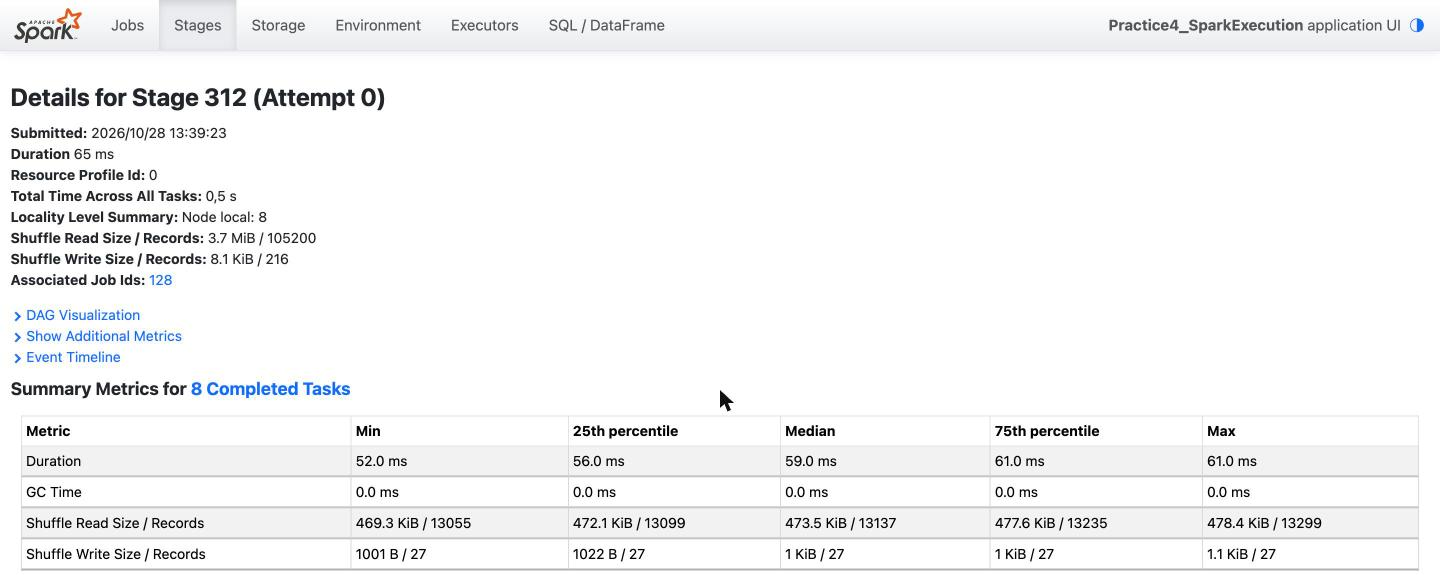

**Вывод.** Группировка `customers` по штату с двумя `countDistinct` дала 3 стадии (3 → 8 → 8 задач), а не 2, как у простого `groupBy`. Для нескольких DISTINCT-агрегатов Spark добавляет `Expand` и двухуровневую агрегацию, а значит, два Exchange. Shuffle первой границы — 3 789,5 KiB: на скриншоте стадии 312 видно 105 200 прочитанных записей при 99 441 строке, потому что Expand размножил строки. Задачи после shuffle сбалансированы (469–478 KiB на задачу). SP — крупнейший штат: 41 746 клиентов.

## 6. JOIN: Sort Merge Join и Broadcast Hash Join

In [38]:
sc.setJobGroup("S_SMJ", "Самостоятельная: SMJ orders x customers")
s_smj = orders.hint("merge").join(customers.hint("merge"), on="customer_id", how="inner")
s_smj.explain("formatted")
print("Rows SMJ:", s_smj.count())
_ = ui_report("S_SMJ", "S: Sort Merge Join")

== Physical Plan ==
* Project (12)
+- * SortMergeJoin Inner (11)
   :- * Sort (5)
   :  +- Exchange (4)
   :     +- * Filter (3)
   :        +- * ColumnarToRow (2)
   :           +- Scan parquet  (1)
   +- * Sort (10)
      +- Exchange (9)
         +- * Filter (8)
            +- * ColumnarToRow (7)
               +- Scan parquet  (6)


(1) Scan parquet 
Output [8]: [order_id#5390, customer_id#5391, order_status#5392, order_purchase_timestamp#5393, order_approved_at#5394, order_delivered_carrier_date#5395, order_delivered_customer_date#5396, order_estimated_delivery_date#5397]
Batched: true
Location: InMemoryFileIndex [file:/Users/nikita/Desktop/Большие данные/4 практика/spark_input_parquet/orders]
PushedFilters: [IsNotNull(customer_id)]
ReadSchema: struct<order_id:string,customer_id:string,order_status:string,order_purchase_timestamp:timestamp,order_approved_at:timestamp,order_delivered_carrier_date:timestamp,order_delivered_customer_date:timestamp,order_estimated_delivery_date:timesta

,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,129,314,COMPLETE,3,25.2,0.0,3287.6,count at DirectMethodHandleAccessor.java:103
1,129,315,COMPLETE,5,47.9,0.0,3287.8,count at DirectMethodHandleAccessor.java:103
2,129,316,COMPLETE,8,0.0,6575.3,0.5,count at DirectMethodHandleAccessor.java:103
3,129,317,COMPLETE,1,0.0,0.5,0.0,count at DirectMethodHandleAccessor.java:103


**Рисунок.** Spark UI → SQL / DataFrame → план orders ⋈ customers как Sort Merge Join

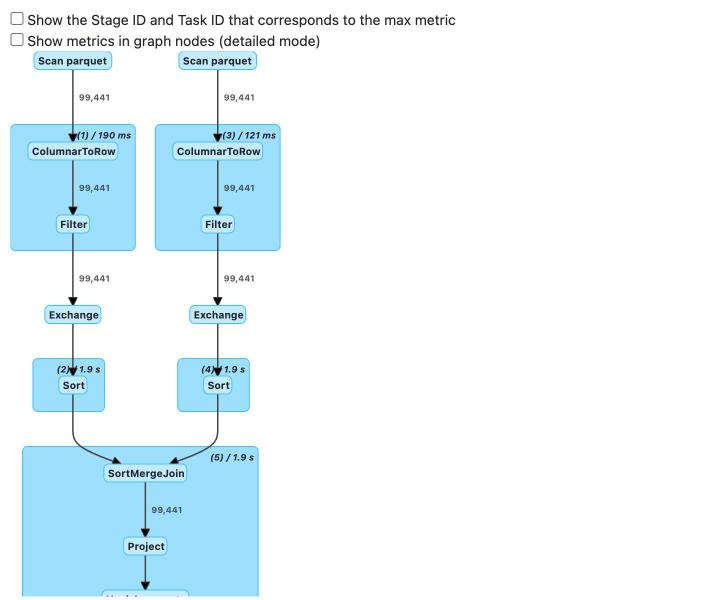

In [39]:
sc.setJobGroup("S_BHJ", "Самостоятельная: BHJ orders x customers")
s_bhj = orders.join(F.broadcast(customers), on="customer_id", how="inner")
s_bhj.explain("formatted")
print("Rows BHJ:", s_bhj.count())
_ = ui_report("S_BHJ", "S: Broadcast Hash Join")

sc.setJobGroup("S_JOIN_TIMING", "Самостоятельная: повторные замеры JOIN")
s_smj_t, s_smj_med = timed(s_smj.count)
s_bhj_t, s_bhj_med = timed(s_bhj.count)

pd.DataFrame({
    "Показатель": ["Строк результата", "Jobs / Stages (complete/skipped)", "Tasks по стадиям",
                   "Shuffle Write / Read, KiB", "Замеры, с", "Медиана, с"],
    "Sort Merge Join": [s_smj.count(),
                        f'{UI_LOG["S: Sort Merge Join"]["Jobs"]} / {UI_LOG["S: Sort Merge Join"]["Stages (complete / skipped)"]}',
                        UI_LOG["S: Sort Merge Join"]["Tasks по стадиям"],
                        f'{UI_LOG["S: Sort Merge Join"]["Shuffle Write, KiB"]} / {UI_LOG["S: Sort Merge Join"]["Shuffle Read, KiB"]}',
                        s_smj_t, s_smj_med],
    "Broadcast Hash Join": [s_bhj.count(),
                            f'{UI_LOG["S: Broadcast Hash Join"]["Jobs"]} / {UI_LOG["S: Broadcast Hash Join"]["Stages (complete / skipped)"]}',
                            UI_LOG["S: Broadcast Hash Join"]["Tasks по стадиям"],
                            f'{UI_LOG["S: Broadcast Hash Join"]["Shuffle Write, KiB"]} / {UI_LOG["S: Broadcast Hash Join"]["Shuffle Read, KiB"]}',
                            s_bhj_t, s_bhj_med],
})

== Physical Plan ==
* Project (9)
+- * BroadcastHashJoin Inner BuildRight (8)
   :- * Filter (3)
   :  +- * ColumnarToRow (2)
   :     +- Scan parquet  (1)
   +- BroadcastExchange (7)
      +- * Filter (6)
         +- * ColumnarToRow (5)
            +- Scan parquet  (4)


(1) Scan parquet 
Output [8]: [order_id#5390, customer_id#5391, order_status#5392, order_purchase_timestamp#5393, order_approved_at#5394, order_delivered_carrier_date#5395, order_delivered_customer_date#5396, order_estimated_delivery_date#5397]
Batched: true
Location: InMemoryFileIndex [file:/Users/nikita/Desktop/Большие данные/4 практика/spark_input_parquet/orders]
PushedFilters: [IsNotNull(customer_id)]
ReadSchema: struct<order_id:string,customer_id:string,order_status:string,order_purchase_timestamp:timestamp,order_approved_at:timestamp,order_delivered_carrier_date:timestamp,order_delivered_customer_date:timestamp,order_estimated_delivery_date:timestamp>

(2) ColumnarToRow [codegen id : 2]
Input [8]: [order_id#5390

,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,130,318,COMPLETE,3,25.2,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Complet
1,131,319,COMPLETE,5,47.9,0.0,0.3,count at DirectMethodHandleAccessor.java:103
2,131,320,COMPLETE,1,0.0,0.3,0.0,count at DirectMethodHandleAccessor.java:103


,Показатель,Sort Merge Join,Broadcast Hash Join
0,Строк результата,99441,99441
1,Jobs / Stages (complete/skipped),1 / 4 / 0,2 / 3 / 0
2,Tasks по стадиям,3 → 5 → 8 → 1,3 → 5 → 1
3,"Shuffle Write / Read, KiB",6575.9 / 6575.8,0.3 / 0.3
4,"Замеры, с","[0.111, 0.089, 0.094]","[0.107, 0.104, 0.105]"
5,"Медиана, с",0.094,0.105


**Вывод.** Оба JOIN вернули 99 441 строку. Sort Merge Join перемешал обе таблицы примерно поровну (3 287 KiB + 3 288 KiB = 6 576 KiB shuffle, 4 стадии). Broadcast Hash Join разослал `customers` отдельным Job и обошёлся без shuffle (0,3 KiB, 3 стадии). Но по времени на моём стенде Sort Merge Join оказался чуть быстрее: медиана 0,094 с против 0,105 с. Обе стороны одного размера, и рассылаемая таблица (около 3 MiB строк) не намного меньше перемешиваемой, поэтому выигрыш broadcast исчезает. Это подтверждает, что broadcast выгоден только при явной асимметрии размеров сторон.

## 7. Cache: persist(MEMORY_AND_DISK)

Промежуточный DataFrame `orders_enriched` (JOIN + вычисляемые признаки) используется двумя действиями: доля
опозданий по штатам и средний срок доставки по месяцам. В отличие от учебной части, кэш **не освобождается сразу**:
он остаётся до последней ячейки, чтобы его можно было увидеть во вкладке Storage Spark UI.

In [40]:
orders_enriched = (
    orders.join(F.broadcast(customers.select("customer_id", "customer_state")), "customer_id", "left")
    .filter(F.col("order_status") == "delivered")
    .withColumn("purchase_ts", F.to_timestamp("order_purchase_timestamp"))
    .withColumn("delivered_ts", F.to_timestamp("order_delivered_customer_date"))
    .withColumn("estimated_ts", F.to_timestamp("order_estimated_delivery_date"))
    .withColumn("delivery_days", F.datediff("delivered_ts", "purchase_ts"))
    .withColumn("is_late", (F.col("delivered_ts") > F.col("estimated_ts")).cast("int"))
    .withColumn("month", F.date_format("purchase_ts", "yyyy-MM"))
)

def s_action_state(df):
    return (df.groupBy("customer_state").agg(F.avg("is_late").alias("late"))
            .agg(F.sum("late")).first()[0])

def s_action_month(df):
    return (df.groupBy("month").agg(F.avg("delivery_days").alias("d"))
            .agg(F.sum("d")).first()[0])

sc.setJobGroup("S_NOCACHE", "Самостоятельная: без кэша")
t0 = perf_counter(); a1 = s_action_state(orders_enriched); t1 = perf_counter()
a2 = s_action_month(orders_enriched); t2 = perf_counter()
s_nocache = (round(t1 - t0, 3), round(t2 - t1, 3))

sc.setJobGroup("S_CACHE", "Самостоятельная: persist + повторные Actions")
orders_cached = orders_enriched.persist(StorageLevel.MEMORY_AND_DISK)
t0 = perf_counter(); n_cached = orders_cached.count(); t1 = perf_counter()
b1 = s_action_state(orders_cached); t2 = perf_counter()
b2 = s_action_month(orders_cached); t3 = perf_counter()
s_cache = (round(t1 - t0, 3), round(t2 - t1, 3), round(t3 - t2, 3))

print("Строк в кэше:", n_cached, "| контрольные суммы совпадают:",
      round(a1, 6) == round(b1, 6) and round(a2, 6) == round(b2, 6))
time.sleep(1.0)
for r in ui_get("storage/rdd"):
    print(f"Storage: {r['storageLevel']} | партиций {r['numCachedPartitions']}/{r['numPartitions']} "
          f"| память {kib(r['memoryUsed'])} KiB | диск {kib(r['diskUsed'])} KiB")
_ = ui_report("S_CACHE", "S: persist + повторный Action")

pd.DataFrame([
    {"Вариант": "Без persist", "Материализация, с": "—", "Action 1, с": s_nocache[0],
     "Action 2, с": s_nocache[1], "Итого, с": round(sum(s_nocache), 3)},
    {"Вариант": "MEMORY_AND_DISK", "Материализация, с": s_cache[0], "Action 1, с": s_cache[1],
     "Action 2, с": s_cache[2], "Итого, с": round(sum(s_cache), 3)},
])

Строк в кэше: 96478 | контрольные суммы совпадают: True
Storage: Disk Memory Serialized 1x Replicated | партиций 5/5 | память 10920.4 KiB | диск 0.0 KiB
[S_CACHE] {'Jobs': 4, 'Stages (complete / skipped)': '9 / 0', 'Tasks по стадиям': '3 → 5 → 1 → 5 → 8 → 1 → 5 → 8 → 1', 'Shuffle Write, KiB': 9.9, 'Shuffle Read, KiB': 9.9}


,job,stage,status,tasks,input_KiB,shuffle_read_KiB,shuffle_write_KiB,name
0,148,357,COMPLETE,3,25.2,0.0,0.0,$anonfun$withThreadLocalCaptured$1 at Complet
1,149,358,COMPLETE,5,382.9,0.0,0.3,count at DirectMethodHandleAccessor.java:103
2,149,359,COMPLETE,1,0.0,0.3,0.0,count at DirectMethodHandleAccessor.java:103
3,150,360,COMPLETE,5,10920.4,0.0,4.5,first at /var/folders/qy/jz75c5852d327vzwrtbp
4,150,361,COMPLETE,8,0.0,4.5,0.5,first at /var/folders/qy/jz75c5852d327vzwrtbp
5,150,362,COMPLETE,1,0.0,0.5,0.0,first at /var/folders/qy/jz75c5852d327vzwrtbp
6,151,363,COMPLETE,5,10920.4,0.0,4.1,first at /var/folders/qy/jz75c5852d327vzwrtbp
7,151,364,COMPLETE,8,0.0,4.1,0.5,first at /var/folders/qy/jz75c5852d327vzwrtbp
8,151,365,COMPLETE,1,0.0,0.5,0.0,first at /var/folders/qy/jz75c5852d327vzwrtbp


,Вариант,"Материализация, с","Action 1, с","Action 2, с","Итого, с"
0,Без persist,—,0.20,0.331,0.531
1,MEMORY_AND_DISK,0.34,0.11,0.087,0.537


**Рисунок.** Spark UI → Storage: закэшированный orders_enriched (MEMORY_AND_DISK)

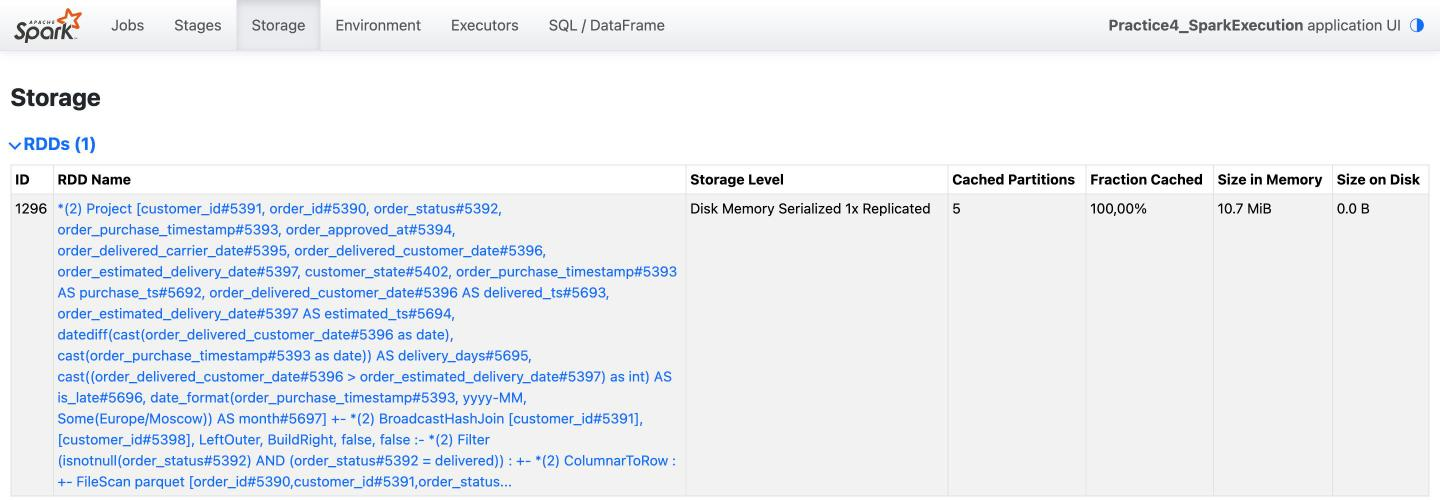

**Вывод.** Закэшированный `orders_enriched` занял 10,7 MiB в памяти (5 из 5 партиций, `MEMORY_AND_DISK`, на диск ничего не ушло); он виден во вкладке Storage. Действия по кэшу выполнялись быстрее (0,110 и 0,087 с против 0,200 и 0,331 с), а их стадии читали 10 920 KiB из кэша вместо JOIN с Parquet. С учётом материализации (0,34 с) итог практически равный: 0,537 с против 0,531 с. Двух действий как раз хватило, чтобы кэш окупился «в ноль»; при третьем и последующих он был бы уже выгоден.

## 8. Benchmark: число партиций

Опыт: `orders.repartition(p)` → BHJ с `customers` → агрегация по `customer_state`. Для каждого p — прогрев
не делается отдельно (общий прогрев JVM уже выполнен в учебной части), 3 замера, медиана.

In [41]:
def s_bench_once(p):
    df = orders.repartition(p).join(F.broadcast(customers), "customer_id")
    t0 = perf_counter()
    df.groupBy("customer_state").agg(F.count("*").alias("n")).agg(F.sum("n")).first()
    return perf_counter() - t0

sc.setJobGroup("S_BENCH", "Самостоятельная: бенчмарк партиций")
s_bench = []
for p in [1, 2, 4, 8, 16, 32]:
    ts = [s_bench_once(p) for _ in range(3)]
    s_bench.append({"p": p, "Run 1, с": round(ts[0], 3), "Run 2, с": round(ts[1], 3),
                    "Run 3, с": round(ts[2], 3), "Median, с": round(median(ts), 3)})
s_bench = pd.DataFrame(s_bench)
s_bench["S(p)"] = (s_bench["Median, с"].iloc[0] / s_bench["Median, с"]).round(2)
s_bench

,p,"Run 1, с","Run 2, с","Run 3, с","Median, с",S(p)
0,1,0.193,0.192,0.175,0.192,1.00
1,2,0.216,0.188,0.188,0.188,1.02
2,4,0.155,0.165,0.161,0.161,1.19
3,8,0.191,0.181,0.160,0.181,1.06
4,16,0.187,0.204,0.207,0.204,0.94
5,32,0.231,0.229,0.244,0.231,0.83


**Вывод.** Лучшая медиана — при p = 4 (0,161 с, S = 1,19). При p = 16 и 32 время выросло до 0,204 и 0,231 с (S < 1). Влияние p здесь слабее, чем в синтетическом бенчмарке: таблица небольшая (99 тыс. строк), а `repartition(p)` сам добавляет shuffle, стоимость которого почти не зависит от p. Основная доля времени приходится на постоянные расходы — чтение, broadcast, планирование.

## 9. Small files: запись итогового DataFrame

In [42]:
state_mart = (
    orders_cached.groupBy("customer_state")
    .agg(F.count("*").alias("delivered"),
         F.round(F.avg("delivery_days"), 2).alias("avg_delivery_days"),
         F.round(F.avg("is_late") * 100, 2).alias("late_pct"))
)
S_OUT = Path("self_experiment_output")
S_OUT.mkdir(exist_ok=True)

sc.setJobGroup("S_WRITE", "Самостоятельная: запись с разным числом партиций")
rows = [write_and_measure(orders_cached, S_OUT / f"orders_enriched_p{p}", p) for p in [1, 8, 32]]
rows.append(write_and_measure(state_mart, S_OUT / "state_mart_p1", 1) | {"p": "1 (витрина)"})
display(pd.DataFrame(rows))
state_mart.orderBy(F.desc("late_pct")).show(5)

,p,part-файлов,"Общий размер, MiB","Средний файл, KiB","Время записи, с"
0,1,1,12.18,12468.5,0.501
1,8,8,12.41,1588.1,0.277
2,32,32,12.52,400.7,0.421
3,1 (витрина),1,0.00,1.9,0.156


+--------------+---------+-----------------+--------+
|customer_state|delivered|avg_delivery_days|late_pct|
+--------------+---------+-----------------+--------+
|            AL|      397|             24.5|   23.93|
|            MA|      717|            21.51|   19.67|
|            PI|      476|            19.39|   15.97|
|            CE|     1279|             21.2|   15.32|
|            SE|      335|            21.46|   15.22|
+--------------+---------+-----------------+--------+
only showing top 5 rows


**Вывод.** Записи с p = 1, 8 и 32 дали ровно 1, 8 и 32 part-файла. Средний размер файла упал с 12,2 MiB до 401 KiB, общий объём вырос незначительно (12,18 → 12,52 MiB). Быстрее всего запись при p = 8 (0,277 с); p = 1 (0,501 с) упирается в одну задачу, p = 32 (0,421 с) — в число файлов. Маленькую витрину по 27 штатам (1,9 KiB) разумно писать одним файлом, а для таблицы на 12 MiB подходит около 8 файлов.

## 10. Выводы и ограничения самостоятельного эксперимента

**Выводы**
1. Ленивое выполнение воспроизвелось и на другой связке таблиц: пять transformations не создали ни одного Job до `count()`.
2. Перекос ключа `order_status` (97 % — delivered) сильнее, чем у `geolocation_state`. После hash-разбиения половина партиций пуста, а `coalesce` сохраняет этот дисбаланс (max/mean = 1,98) и даже оставляет пустую партицию.
3. Несколько `countDistinct` в одной агрегации добавляют `Expand` и вторую границу shuffle: 3 стадии вместо 2, а объём shuffle (3,7 MiB) больше размера исходных данных.
4. Для двух таблиц одинакового размера Broadcast Hash Join убрал 6,4 MiB shuffle, но не ускорил запрос (0,105 с против 0,094 с у Sort Merge Join): стоимость рассылки сопоставима со стоимостью обмена.
5. Кэш промежуточного JOIN ускорил каждое повторное действие примерно в 2–4 раза, но с учётом материализации окупился только к концу второго действия.
6. Для таблицы около 100 тыс. строк оптимальное число партиций — около 4. Дальнейшее дробление (16–32) только добавляет накладные расходы, а при записи создаёт лишние мелкие файлы.

**Ограничения**
1. Объём данных небольшой (99 тыс. строк, около 12 MiB). Все времена — доли секунды, на уровне шума планировщика и прогрева JVM, поэтому разница в 10–20 мс не является устойчивым результатом.
2. Опыт выполнен в local[*] на одном компьютере: сетевой стоимости shuffle и broadcast нет, и на кластере соотношение Sort Merge Join и Broadcast Hash Join может быть другим.
3. Каждая серия повторялась 3 раза. Для статистически надёжных выводов нужно больше повторов и большие объёмы данных.

# Ответы на контрольные вопросы

**1. Transformation vs action.** Transformation (`select`, `filter`, `withColumn`, `groupBy`, `join`) только
добавляет узел в план и возвращает новый DataFrame; вычисление не начинается. Action (`count`, `collect`, `show`,
`first`, `write`) требует результат и запускает Job.

**2. Lazy evaluation и замер вокруг `withColumn()`.** Spark откладывает вычисление до action, чтобы оптимизировать
план целиком. Замер вокруг `withColumn()` без action измеряет лишь построение плана в драйвере (миллисекунды,
п. 5.1), а не обработку данных.

**3. Job, Stage, Task.** Один action порождает один или несколько Jobs; Job делится на Stages по границам shuffle;
Stage состоит из Tasks — по одной на партицию этой стадии.

**4. Почему число Tasks в Stages различается.** Число задач равно числу партиций стадии: до shuffle — числу входных
партиций (файлов/сплитов), после shuffle — `spark.sql.shuffle.partitions` или числу из `repartition`/`coalesce`.

**5. Partition vs CPU core.** Partition — логическая часть данных (единица работы), core — физический ресурс, который
выполняет задачу. Партиций может быть больше или меньше, чем ядер; одновременно выполняется min(C, p) задач.

**6. Почему local[*] сохраняет модель.** Driver, планировщик, разбиение на Jobs/Stages/Tasks, shuffle-файлы и
планы Catalyst те же; меняется только то, что executors — потоки одной JVM, а обмен идёт через локальный диск.

**7. Narrow и wide.** Narrow — выходная партиция зависит от ограниченного числа входных (`filter`, `select`,
`withColumn`, `coalesce`). Wide — требует перераспределения по ключу (`groupBy`, `distinct`, `repartition`, большинство JOIN).

**8. Shuffle и его стоимость.** Shuffle — перераспределение строк между партициями: сериализация, запись
промежуточных файлов, передача (в кластере — по сети), чтение и десериализация. `filter/select` работают внутри
партиции без этого обмена.

**9. Exchange и shuffle.** Оператор `Exchange` в физическом плане — это и есть точка shuffle и граница стадий
(`hashpartitioning`, `RoundRobinPartitioning`, `rangepartitioning`).

**10. repartition vs coalesce.** `repartition(n)` выполняет полный shuffle и может увеличивать/уменьшать число партиций,
выравнивая их; `coalesce(n)` только склеивает соседние партиции без shuffle — дешевле, но без балансировки.

**11. Почему coalesce сохраняет неравномерность.** Он объединяет существующие партиции целиком, не перемешивая строки;
если исходные партиции были разного размера (перекос ключа), объединённые тоже будут разными (табл. 4).

**12. Data skew на geolocation_state.** Перекос — неравномерность ключа: на SP приходится около 40 % строк
`geolocation`, поэтому при разбиении по штату одна партиция получает непропорционально много данных и её задача
выполняется дольше остальных.

**13. spark.sql.shuffle.partitions.** Задаёт число партиций после SQL-shuffle (groupBy, join). Число входных партиций
определяется файлами Parquet и размером сплитов и этой настройкой не меняется.

**14. Операторы explain("formatted").** Scan (чтение), Filter, Project, Exchange (shuffle), Sort, HashAggregate
(частичная/финальная агрегация), SortMergeJoin / BroadcastHashJoin, BroadcastExchange, Coalesce, InMemoryTableScan.

**15. Exchange и Sort в SMJ.** Sort Merge Join требует, чтобы одинаковые ключи обеих сторон лежали в одних партициях
(Exchange hashpartitioning по ключу) и были отсортированы (Sort) — только тогда возможно слияние.

**16. Когда выгоден BHJ.** Когда одна сторона достаточно мала, чтобы целиком поместиться в память каждого executor:
большая сторона не перемешивается, JOIN выполняется локально по hash-таблице.

**17. Почему большую таблицу нельзя broadcast-ить.** Её нужно собрать на драйвере и разослать всем executors: растут
время передачи и расход памяти, возможны OutOfMemory и падение драйвера.

**18. Зачем одинаковое число строк при сравнении JOIN.** Это проверка логической эквивалентности: сравнивается
физическая стратегия одного и того же результата, а не разные запросы.

**19. Первый action после persist().** `persist()` только помечает DataFrame; первый action вычисляет его по lineage
и параллельно сохраняет партиции в память/на диск. Последующие actions читают кэш (`InMemoryTableScan`).

**20. Почему cache может ухудшить одноразовую задачу.** Материализация требует дополнительной сериализации и памяти;
если результат используется один раз, затраты не окупаются и могут вытеснить другие данные из памяти.

**21. Зачем unpersist().** Освободить память/диск executors после использования, чтобы кэш не вытеснял другие данные
и не искажал следующие эксперименты.

**22. Почему нужна медиана.** Время одного запуска зависит от прогрева JVM, JIT, файлового кэша ОС и фоновой нагрузки;
медиана нескольких запусков устойчива к единичным выбросам.

**23. Что делает время несопоставимым между компьютерами.** CPU и число ядер, объём памяти, тип диска, версии Java и
Spark, настройки сессии, фоновая нагрузка, прогрев JVM, файловый кэш ОС.

**24. Почему много партиций увеличивает overhead.** Каждая задача требует планирования, сериализации замыкания,
запуска и отчёта; при очень мелких партициях эти постоянные затраты превышают полезную работу.

**25. Output partitions, Tasks и part-файлы.** Каждая партиция при записи обрабатывается своей задачей, которая пишет
свой part-файл; поэтому число файлов ≈ числу выходных партиций (табл. 9).

**26. Почему coalesce(1) не решает small files.** Он убирает параллелизм записи: вся работа идёт одной задачей и для
больших данных становится узким местом по времени и памяти, а последующее чтение одного большого файла хуже
распараллеливается.

**27. AQE.** Adaptive Query Execution по статистике уже выполненных стадий объединяет мелкие shuffle-партиции, меняет
стратегию JOIN и обрабатывает перекос. В основных опытах он выключен, чтобы наблюдать эффект именно заданных параметров.

**28. Полезные вкладки Spark UI.** Для groupBy — Jobs/Stages (число задач, Shuffle Read/Write); для JOIN — SQL /
DataFrame (граф плана с Exchange/BroadcastExchange) и Stages; для cache — Storage (уровень хранения, объём) и
SKIPPED-стадии в Jobs.

**29. Вывод о данных vs вывод о системе.** Вывод о данных описывает сам набор (сколько, как распределено); вывод о
системе описывает, как конкретная конфигурация Spark обработала данные (план, стадии, время) — он условен по отношению
к стенду и настройкам.

**30. Корректный вывод о производительности.** Указать данные, конфигурацию, что менялось, число повторов и медиану,
связать время с механизмом (Exchange, Tasks, Shuffle) и явно ограничить вывод своим стендом: «на моём стенде при …
наблюдалось …», а не «X всегда быстрее Y».

## Практический блок 19.1. Завершение сессии

Скриншоты Spark UI сняты до этой ячейки (UI работает, пока жива SparkSession). Ниже освобождается кэш
самостоятельной части и останавливается сессия.

In [43]:
print("Spark UI:", sc.uiWebUrl, "| application:", sc.applicationId)

Spark UI: http://localhost:4040 | application: local-1793183924087


In [44]:
orders_cached.unpersist(blocking=True)
spark.stop()
print("SparkSession остановлена")

SparkSession остановлена
